# C04c — Step 10 CARDINAL Audit

This notebook starts **Step 10** of the frozen-FZ301 intervention sequence.

Input is the accepted **post-Step-9 ORG Referential Explicitization** text from C04b.
This notebook is **audit only**: it does not yet edit CARDINAL mentions or use the
detector to select candidate rewrites.

The audit answers:

1. What exactly do the four frozen FZ301 `ner_CARDINAL_*` coordinates measure?
2. Are post-Step-9 texts above or below their same-genre human references?
3. Which CARDINAL coordinate contributes the largest remaining AI-directed gap?
4. Which documents and sentences create the extreme CARDINAL values?
5. What does spaCy actually label as `CARDINAL` in the current texts?

The four coordinates are:

- `ner_CARDINAL_entity_share`
- `ner_CARDINAL_sentence_mean`
- `ner_CARDINAL_sentence_std`
- `ner_CARDINAL_sentence_max`

We retain the C04 frozen detector, feature contract, fixed human test/reference
population, and the same 54-source intervention cohort.


In [1]:
from pathlib import Path
import json, pickle, re
from collections import Counter

import numpy as np
import pandas as pd
import spacy

from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent

BASE = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid"
C04_ROOT = ROOT / "results/causal/C04_fz301_raid_fixed54"
C04B_ROOT = ROOT / "results/causal/C04b_ORG_referential_explicitization"
OUT = ROOT / "results/causal/C04c_CARDINAL_audit"
OUT.mkdir(parents=True, exist_ok=True)

normalize = lambda t: str(t).replace("\n", " ").replace("\r", " ")

# Exact spaCy model used by the frozen C04/C04b NER block.
nlp = spacy.load("en_core_web_sm")

# ---------------------------------------------------------------------
# Find the accepted C04 frozen-FZ301 baseline.
# ---------------------------------------------------------------------
c04_runs = []
for p in sorted(C04_ROOT.glob("*")):
    if not p.is_dir():
        continue
    if not (p / "FZ301.pkl").exists() or not (p / "stage_summary.csv").exists():
        continue

    s = pd.read_csv(p / "stage_summary.csv")
    if (
        len(s) == 3
        and np.isclose(float(s.iloc[0]["AUROC"]), 0.875380, atol=5e-6)
        and np.isclose(float(s.iloc[2]["AUROC"]), 0.699558, atol=5e-6)
    ):
        c04_runs.append(p)

assert len(c04_runs) == 1, (
    "Expected exactly one accepted C04 frozen-FZ301 run. Found:\n"
    + "\n".join(map(str, c04_runs))
)
C04_RUN = c04_runs[0]

C04_CONTRACT = json.loads((C04_RUN / "contract.json").read_text())
C04_MANIFEST = json.loads((C04_RUN / "feature_manifest.json").read_text())

with (C04_RUN / "FZ301.pkl").open("rb") as f:
    fz301 = pickle.load(f)

# ---------------------------------------------------------------------
# Find the accepted C04b Step-9 endpoint.
# Rejected/no-effect C04b pilot hashes are deliberately ignored.
# ---------------------------------------------------------------------
c04b_runs = []
for p in sorted(C04B_ROOT.glob("*")):
    if not p.is_dir():
        continue

    summary_path = p / "evaluation_summary.csv"
    text_path = p / "texts_after_ORG_explicitization.csv"
    contrib_path = p / "step8_vs_step9_contributions.csv"

    if not (summary_path.exists() and text_path.exists() and contrib_path.exists()):
        continue

    s = pd.read_csv(summary_path)
    row = s.loc[s["stage"].astype(str).str.contains("Step 9", regex=False)]
    if (
        len(row) == 1
        and np.isclose(float(row.iloc[0]["AUROC"]), 0.6970093122, atol=5e-6)
        and np.isclose(float(row.iloc[0]["mean_AI_score"]), 0.4983782026, atol=5e-6)
    ):
        c04b_runs.append(p)

assert len(c04b_runs) == 1, (
    "Expected exactly one accepted C04b Step-9 run. Found:\n"
    + "\n".join(map(str, c04b_runs))
)
C04B_RUN = c04b_runs[0]

step9 = (
    pd.read_csv(C04B_RUN / "texts_after_ORG_explicitization.csv", keep_default_na=False)
    .sort_values("case_id")
    .reset_index(drop=True)
)

assert len(step9) == 54
assert step9.case_id.is_unique
assert step9.source_id.is_unique

human_test_manifest = pd.read_csv(C04_RUN / "human_test_manifest.csv")

CACHE = (
    ROOT
    / "results/causal/C04_fz301_feature_cache"
    / C04_CONTRACT["feature_manifest_hash"]
)
assert (CACHE / "raid_extensions.parquet").exists()

raid_ext_cache = (
    pd.read_parquet(CACHE / "raid_extensions.parquet")
    .set_index("source_id")
)

CARDINAL_FEATURES = [
    "ner_CARDINAL_entity_share",
    "ner_CARDINAL_sentence_mean",
    "ner_CARDINAL_sentence_std",
    "ner_CARDINAL_sentence_max",
]

print("Accepted C04 run :", C04_RUN.relative_to(ROOT))
print("Accepted C04b run:", C04B_RUN.relative_to(ROOT))
print("Step-9 texts     :", C04B_RUN.joinpath("texts_after_ORG_explicitization.csv").relative_to(ROOT))
print("Audit output     :", OUT.relative_to(ROOT))


Accepted C04 run : results/causal/C04_fz301_raid_fixed54/d6c459f7c8a2
Accepted C04b run: results/causal/C04b_ORG_referential_explicitization/c3a89a200711
Step-9 texts     : results/causal/C04b_ORG_referential_explicitization/c3a89a200711/texts_after_ORG_explicitization.csv
Audit output     : results/causal/C04c_CARDINAL_audit


In [2]:
# Exact four-stat NER block used for the CARDINAL audit.
#
# We validate this implementation against the ORG statistics already saved by
# the accepted C04b notebook before trusting it for CARDINAL.

def ner_stats_for_label(text, label):
    doc = nlp(normalize(text))
    sentences = list(doc.sents)
    ents = list(doc.ents)

    overall = Counter(ent.label_ for ent in ents)

    # Zero-count sentences are retained.
    sent_counts = []
    for sent in sentences:
        c = Counter(
            ent.label_
            for ent in ents
            if ent.start >= sent.start and ent.end <= sent.end
        )
        sent_counts.append(c)

    a = np.asarray([c[label] for c in sent_counts], dtype=float)

    entity_share = (
        float(overall[label]) / float(len(ents))
        if len(ents)
        else 0.0
    )

    sentence_mean = float(a.mean()) if len(a) else 0.0
    sentence_std = float(a.std(ddof=0)) if len(a) else 0.0
    sentence_max = float(a.max()) if len(a) else 0.0

    return {
        f"ner_{label}_entity_share": entity_share,
        f"ner_{label}_sentence_mean": sentence_mean,
        f"ner_{label}_sentence_std": sentence_std,
        f"ner_{label}_sentence_max": sentence_max,
        f"n_{label}": int(overall[label]),
        "n_entities": int(len(ents)),
        "n_sentences_spacy": int(len(sentences)),
    }


# Validate against C04b's already-saved post-edit ORG values on all 54 texts.
org_recomputed = pd.DataFrame(
    [ner_stats_for_label(t, "ORG") for t in step9.text]
)

validation_pairs = {
    "ner_ORG_entity_share": "after_ORG_entity_share",
    "ner_ORG_sentence_mean": "after_ORG_sentence_mean",
    "ner_ORG_sentence_std": "after_ORG_sentence_std",
    "ner_ORG_sentence_max": "after_ORG_sentence_max",
}

for recomputed_col, saved_col in validation_pairs.items():
    np.testing.assert_allclose(
        org_recomputed[recomputed_col].to_numpy(float),
        step9[saved_col].to_numpy(float),
        atol=1e-12,
        rtol=0,
        err_msg=f"NER audit extractor mismatch for {recomputed_col}",
    )

np.testing.assert_array_equal(
    org_recomputed["n_ORG"].to_numpy(int),
    step9["after_n_ORG"].to_numpy(int),
)

print("✓ Exact NER-stat extractor validated against all 54 saved C04b ORG rows.")


✓ Exact NER-stat extractor validated against all 54 saved C04b ORG rows.


In [3]:
# Compute post-Step-9 CARDINAL values and fixed-human references.

cardinal_ai = pd.DataFrame(
    [ner_stats_for_label(t, "CARDINAL") for t in step9.text]
)

cardinal_ai.insert(0, "domain", step9.domain.to_numpy())
cardinal_ai.insert(0, "source_id", step9.source_id.to_numpy())
cardinal_ai.insert(0, "case_id", step9.case_id.to_numpy())

human_cardinal = (
    human_test_manifest[["source_id", "domain", "weight"]]
    .merge(
        raid_ext_cache[CARDINAL_FEATURES].reset_index(),
        on="source_id",
        how="left",
        validate="one_to_one",
    )
)

assert human_cardinal[CARDINAL_FEATURES].notna().all().all()

def q10(x): return float(np.quantile(x, 0.10))
def q25(x): return float(np.quantile(x, 0.25))
def q75(x): return float(np.quantile(x, 0.75))
def q90(x): return float(np.quantile(x, 0.90))

# Long-form human reference table, one row per domain x feature.
human_reference_rows = []
for domain, g in human_cardinal.groupby("domain", sort=True):
    for feature in CARDINAL_FEATURES:
        vals = g[feature].to_numpy(float)
        human_reference_rows.append({
            "domain": domain,
            "feature": feature,
            "n_human": len(vals),
            "mean": float(vals.mean()),
            "median": float(np.median(vals)),
            "std": float(vals.std(ddof=0)),
            "q10": q10(vals),
            "q25": q25(vals),
            "q75": q75(vals),
            "q90": q90(vals),
            "min": float(vals.min()),
            "max": float(vals.max()),
        })

human_reference = pd.DataFrame(human_reference_rows)

# Add same-genre reference values to every AI case.
cardinal_case_audit = cardinal_ai.copy()

for feature in CARDINAL_FEATURES:
    ref = human_reference.loc[
        human_reference.feature.eq(feature)
    ].set_index("domain")

    cardinal_case_audit[f"{feature}_human_mean"] = (
        cardinal_case_audit.domain.map(ref["mean"])
    )
    cardinal_case_audit[f"{feature}_human_median"] = (
        cardinal_case_audit.domain.map(ref["median"])
    )
    cardinal_case_audit[f"{feature}_human_q10"] = (
        cardinal_case_audit.domain.map(ref["q10"])
    )
    cardinal_case_audit[f"{feature}_human_q25"] = (
        cardinal_case_audit.domain.map(ref["q25"])
    )
    cardinal_case_audit[f"{feature}_human_q75"] = (
        cardinal_case_audit.domain.map(ref["q75"])
    )
    cardinal_case_audit[f"{feature}_human_q90"] = (
        cardinal_case_audit.domain.map(ref["q90"])
    )

    cardinal_case_audit[f"{feature}_delta_mean"] = (
        cardinal_case_audit[feature]
        - cardinal_case_audit[f"{feature}_human_mean"]
    )
    cardinal_case_audit[f"{feature}_delta_median"] = (
        cardinal_case_audit[feature]
        - cardinal_case_audit[f"{feature}_human_median"]
    )

# Genre-matched aggregate summary.
overall_rows = []
for feature in CARDINAL_FEATURES:
    ai_vals = cardinal_case_audit[feature].to_numpy(float)
    matched_human_means = cardinal_case_audit[f"{feature}_human_mean"].to_numpy(float)
    matched_human_medians = cardinal_case_audit[f"{feature}_human_median"].to_numpy(float)

    overall_rows.append({
        "feature": feature,
        "AI_mean": float(ai_vals.mean()),
        "AI_median": float(np.median(ai_vals)),
        "matched_human_mean": float(matched_human_means.mean()),
        "mean_delta": float((ai_vals - matched_human_means).mean()),
        "matched_human_median_mean": float(matched_human_medians.mean()),
        "fraction_above_same_genre_median": float(
            np.mean(ai_vals > matched_human_medians)
        ),
        "fraction_equal_same_genre_median": float(
            np.mean(np.isclose(ai_vals, matched_human_medians))
        ),
        "fraction_below_same_genre_median": float(
            np.mean(ai_vals < matched_human_medians)
        ),
    })

overall_summary = pd.DataFrame(overall_rows)

print("Post-Step-9 CARDINAL vs same-genre human reference:")
display(overall_summary)


Post-Step-9 CARDINAL vs same-genre human reference:


,feature,AI_mean,AI_median,matched_human_mean,mean_delta,matched_human_median_mean,fraction_above_same_genre_median,fraction_equal_same_genre_median,fraction_below_same_genre_median
0,ner_CARDINAL_entity_share,0.161229,0.065126,0.194620,-0.033391,0.170034,0.314815,0.111111,0.574074
1,ner_CARDINAL_sentence_mean,0.245416,0.125000,0.303965,-0.058549,0.246877,0.351852,0.074074,0.574074
2,ner_CARDINAL_sentence_std,0.504495,0.330719,0.666241,-0.161746,0.645528,0.277778,0.074074,0.648148
3,ner_CARDINAL_sentence_max,1.777778,1.000000,2.427801,-0.650023,2.222222,0.111111,0.462963,0.425926


In [4]:
# Domain-level raw-value audit.
# This makes it easy to see whether one genre drives the aggregate result.

domain_rows = []

for domain, ai_g in cardinal_case_audit.groupby("domain", sort=True):
    h_g = human_cardinal.loc[human_cardinal.domain.eq(domain)]

    for feature in CARDINAL_FEATURES:
        ai_vals = ai_g[feature].to_numpy(float)
        h_vals = h_g[feature].to_numpy(float)
        h_med = float(np.median(h_vals))

        domain_rows.append({
            "domain": domain,
            "feature": feature,
            "n_AI": len(ai_vals),
            "n_human": len(h_vals),
            "AI_mean": float(ai_vals.mean()),
            "AI_median": float(np.median(ai_vals)),
            "human_mean": float(h_vals.mean()),
            "human_median": h_med,
            "mean_delta": float(ai_vals.mean() - h_vals.mean()),
            "fraction_AI_above_human_median": float(np.mean(ai_vals > h_med)),
            "fraction_AI_below_human_median": float(np.mean(ai_vals < h_med)),
        })

domain_summary = pd.DataFrame(domain_rows)

for feature in CARDINAL_FEATURES:
    print("\n", "=" * 100)
    print(feature)
    display(
        domain_summary.loc[domain_summary.feature.eq(feature)]
        .drop(columns="feature")
        .reset_index(drop=True)
    )



ner_CARDINAL_entity_share


,domain,n_AI,n_human,AI_mean,AI_median,human_mean,human_median,mean_delta,fraction_AI_above_human_median,fraction_AI_below_human_median
0,abstracts,10,23,0.152222,0.083333,0.210168,0.166667,-0.057946,0.400000,0.500000
1,books,7,18,0.035265,0.000000,0.108799,0.076923,-0.073533,0.142857,0.714286
2,news,12,25,0.090715,0.066239,0.111372,0.097561,-0.020657,0.250000,0.750000
3,recipes,9,21,0.533334,0.560000,0.523064,0.595745,0.010270,0.333333,0.666667
4,reddit,6,16,0.103175,0.000000,0.128795,0.000000,-0.025620,0.333333,0.000000
5,reviews,1,6,0.000000,0.000000,0.091688,0.098140,-0.091688,0.000000,1.000000
6,wiki,9,19,0.047741,0.034483,0.081970,0.038462,-0.034229,0.444444,0.555556



ner_CARDINAL_sentence_mean


,domain,n_AI,n_human,AI_mean,AI_median,human_mean,human_median,mean_delta,fraction_AI_above_human_median,fraction_AI_below_human_median
0,abstracts,10,23,0.216667,0.125000,0.196266,0.125000,0.020400,0.500000,0.500000
1,books,7,18,0.044322,0.000000,0.170371,0.154762,-0.126049,0.142857,0.857143
2,news,12,25,0.215801,0.125000,0.221240,0.222222,-0.005439,0.250000,0.750000
3,recipes,9,21,0.755903,0.777778,0.768261,0.772727,-0.012359,0.555556,0.444444
4,reddit,6,16,0.041667,0.000000,0.062706,0.000000,-0.021040,0.333333,0.000000
5,reviews,1,6,0.000000,0.000000,0.100350,0.091093,-0.100350,0.000000,1.000000
6,wiki,9,19,0.125866,0.090909,0.357004,0.142857,-0.231138,0.333333,0.666667



ner_CARDINAL_sentence_std


,domain,n_AI,n_human,AI_mean,AI_median,human_mean,human_median,mean_delta,fraction_AI_above_human_median,fraction_AI_below_human_median
0,abstracts,10,23,0.280883,0.216506,0.328396,0.330719,-0.047512,0.500000,0.500000
1,books,7,18,0.126942,0.000000,0.340646,0.361303,-0.213704,0.142857,0.857143
2,news,12,25,0.378653,0.330719,0.401991,0.415740,-0.023338,0.250000,0.750000
3,recipes,9,21,1.770362,1.787925,2.152060,2.288592,-0.381698,0.111111,0.888889
4,reddit,6,16,0.110240,0.000000,0.145545,0.000000,-0.035305,0.333333,0.000000
5,reviews,1,6,0.000000,0.000000,0.247504,0.286681,-0.247504,0.000000,1.000000
6,wiki,9,19,0.267419,0.287480,0.555035,0.349927,-0.287616,0.333333,0.666667



ner_CARDINAL_sentence_max


,domain,n_AI,n_human,AI_mean,AI_median,human_mean,human_median,mean_delta,fraction_AI_above_human_median,fraction_AI_below_human_median
0,abstracts,10,23,0.700000,0.5,0.913043,1.0,-0.213043,0.100000,0.500000
1,books,7,18,0.428571,0.0,0.944444,1.0,-0.515873,0.000000,0.571429
2,news,12,25,1.083333,1.0,1.280000,1.0,-0.196667,0.083333,0.250000
3,recipes,9,21,7.111111,8.0,9.095238,9.0,-1.984127,0.111111,0.777778
4,reddit,6,16,0.333333,0.0,0.437500,0.0,-0.104167,0.333333,0.000000
5,reviews,1,6,0.000000,0.0,0.833333,1.0,-0.833333,0.000000,1.000000
6,wiki,9,19,0.777778,1.0,1.631579,1.0,-0.853801,0.111111,0.333333


In [5]:
# How does the frozen FZ301 forest currently use the CARDINAL family?
#
# These are the exact post-Step-8 vs post-Step-9 mean contribution gaps saved
# by the accepted C04b run. Positive Step9_gap = AI-directed relative to the
# fixed same-genre human contribution reference.

contribution_all = pd.read_csv(
    C04B_RUN / "step8_vs_step9_contributions.csv"
)

contribution_all["Step9_positive_rank"] = (
    contribution_all["Step9_gap"]
    .rank(method="min", ascending=False)
    .astype(int)
)

cardinal_contribution = (
    contribution_all.loc[
        contribution_all.feature.isin(CARDINAL_FEATURES),
        [
            "feature",
            "Step8_gap",
            "Step9_gap",
            "Step9_ci_low",
            "Step9_ci_high",
            "Step9_minus_Step8",
            "Step9_positive_rank",
        ],
    ]
    .sort_values("Step9_gap", ascending=False)
    .reset_index(drop=True)
)

print("Frozen-FZ301 CARDINAL contribution gaps after Step 9:")
display(cardinal_contribution)

print(
    "\nLargest CARDINAL residual:",
    cardinal_contribution.iloc[0]["feature"],
    "gap =",
    cardinal_contribution.iloc[0]["Step9_gap"],
)


Frozen-FZ301 CARDINAL contribution gaps after Step 9:


,feature,Step8_gap,Step9_gap,Step9_ci_low,Step9_ci_high,Step9_minus_Step8,Step9_positive_rank
0,ner_CARDINAL_sentence_max,0.002307,0.002319,0.001016,0.003549,0.000012,1
1,ner_CARDINAL_sentence_std,0.001798,0.001764,0.000626,0.002848,-0.000034,7
2,ner_CARDINAL_sentence_mean,0.001630,0.001610,0.000471,0.002773,-0.000020,10
3,ner_CARDINAL_entity_share,0.001643,0.001609,0.000167,0.002935,-0.000034,11



Largest CARDINAL residual: ner_CARDINAL_sentence_max gap = 0.0023193871843945


In [6]:
# Place every AI case into the same human-relative bands used in the ORG audit.

def relative_band(value, q10_, q25_, q75_, q90_):
    if value < q10_:
        return "<q10"
    if value < q25_:
        return "q10-q25"
    if value <= q75_:
        return "q25-q75"
    if value <= q90_:
        return "q75-q90"
    return ">q90"

band_rows = []

for feature in CARDINAL_FEATURES:
    for row in cardinal_case_audit.itertuples(index=False):
        band = relative_band(
            getattr(row, feature),
            getattr(row, f"{feature}_human_q10"),
            getattr(row, f"{feature}_human_q25"),
            getattr(row, f"{feature}_human_q75"),
            getattr(row, f"{feature}_human_q90"),
        )
        band_rows.append({
            "case_id": row.case_id,
            "domain": row.domain,
            "feature": feature,
            "raw_value": getattr(row, feature),
            "human_relative_band": band,
        })

cardinal_bands = pd.DataFrame(band_rows)

band_summary = (
    cardinal_bands
    .groupby(["feature", "human_relative_band"], observed=True)
    .agg(
        n=("case_id", "size"),
        mean_raw_value=("raw_value", "mean"),
    )
    .reset_index()
)

band_order = ["<q10", "q10-q25", "q25-q75", "q75-q90", ">q90"]
band_summary["human_relative_band"] = pd.Categorical(
    band_summary["human_relative_band"],
    categories=band_order,
    ordered=True,
)
band_summary = band_summary.sort_values(
    ["feature", "human_relative_band"]
).reset_index(drop=True)

display(band_summary)


,feature,human_relative_band,n,mean_raw_value
0,ner_CARDINAL_entity_share,<q10,1,0.217391
1,ner_CARDINAL_entity_share,q10-q25,8,0.000000
2,ner_CARDINAL_entity_share,q25-q75,37,0.137525
3,ner_CARDINAL_entity_share,q75-q90,5,0.322055
4,ner_CARDINAL_entity_share,>q90,3,0.596761
5,ner_CARDINAL_sentence_max,q10-q25,9,0.333333
6,ner_CARDINAL_sentence_max,q25-q75,42,1.976190
7,ner_CARDINAL_sentence_max,q75-q90,1,2.000000
8,ner_CARDINAL_sentence_max,>q90,2,4.000000
9,ner_CARDINAL_sentence_mean,<q10,1,0.217391


In [7]:
# Inspect what spaCy is actually calling CARDINAL.
#
# We retain sentence context because intervention design will depend heavily on
# whether the high-count cases are ordinary quantities, years, list-like
# concentrations, repeated counts, or other constructions.

mention_rows = []
sentence_rows = []

for row in step9.itertuples(index=False):
    doc = nlp(normalize(row.text))

    for sent_idx, sent in enumerate(doc.sents):
        cards = [ent for ent in sent.ents if ent.label_ == "CARDINAL"]
        if not cards:
            continue

        surfaces = [ent.text for ent in cards]

        sentence_rows.append({
            "case_id": row.case_id,
            "domain": row.domain,
            "sentence_index": sent_idx,
            "n_CARDINAL": len(cards),
            "CARDINAL_surfaces": " | ".join(surfaces),
            "sentence": sent.text.strip(),
        })

        for ent in cards:
            surface = ent.text.strip()
            mention_rows.append({
                "case_id": row.case_id,
                "domain": row.domain,
                "sentence_index": sent_idx,
                "surface": surface,
                "surface_lower": surface.lower(),
                "contains_digit": bool(re.search(r"\d", surface)),
                "word_only": bool(re.fullmatch(r"[A-Za-z][A-Za-z\s'-]*", surface)),
                "sentence": sent.text.strip(),
            })

cardinal_mentions = pd.DataFrame(mention_rows)
cardinal_sentences = pd.DataFrame(sentence_rows)

print("Cases with >=1 CARDINAL:", cardinal_mentions.case_id.nunique(), "/ 54")
print("Total CARDINAL mentions :", len(cardinal_mentions))
print("CARDINAL-bearing sentences:", len(cardinal_sentences))

if len(cardinal_mentions):
    print("\nSurface-form type:")
    display(
        cardinal_mentions.assign(
            surface_type=np.where(
                cardinal_mentions.contains_digit,
                "digit-containing",
                np.where(cardinal_mentions.word_only, "word-only", "other"),
            )
        )["surface_type"]
        .value_counts()
        .rename_axis("surface_type")
        .reset_index(name="n")
    )

    print("\nMost common CARDINAL surfaces:")
    display(
        cardinal_mentions["surface_lower"]
        .value_counts()
        .head(40)
        .rename_axis("surface")
        .reset_index(name="n")
    )

    print("\nSentences with the most CARDINAL mentions:")
    display(
        cardinal_sentences
        .sort_values(
            ["n_CARDINAL", "case_id", "sentence_index"],
            ascending=[False, True, True],
        )
        .head(40)
        .reset_index(drop=True)
    )


Cases with >=1 CARDINAL: 34 / 54
Total CARDINAL mentions : 168
CARDINAL-bearing sentences: 91

Surface-form type:


,surface_type,n
0,digit-containing,124
1,word-only,44



Most common CARDINAL surfaces:


,surface,n
0,2,22
1,1,19
2,one,12
3,two,12
4,3,10
5,6,9
6,4,8
7,1/2,8
8,1/4,5
9,2d,5



Sentences with the most CARDINAL mentions:


,case_id,domain,sentence_index,n_CARDINAL,CARDINAL_surfaces,sentence
0,gate_0025,recipes,0,11,One | 2 | 2 | 1 | 1 | 1/2 | 1/2 | 1/2 | 1/4 | ...,"Ingredients, For the dumplings One 16-ounce pa..."
1,gate_0037,recipes,0,9,2 | 1 | 2 | 2 | 3 | 1 | 1 | 2 | 2,Flemish Beef Roast (Or Stew) with Vegetables R...
2,gate_0004,recipes,0,8,4 | 4 | 6 | leaves - One 4 | 2 | 1 | 1 | 4,"- 8-1/2 cups water, divided - 4 small carrots,..."
3,gate_0049,recipes,0,8,1 | 6 | 4 | 4 | 1/2 | 1/2 | 1/2 | 1/4,Asparagus with Prosciutto di Parma Pecorino Pe...
4,gate_0085,recipes,0,8,3 | 1/2 | 1/4 | 1/4 | 8 | 2 | 400 | 2,"Ingredients, 1 head of broccoli cut into small..."
5,gate_0049,recipes,21,7,three hundred eighty-three | 29 | 443 | 6 | 1 ...,"Nutrition Facts Calories, three hundred eighty..."
6,gate_0081,recipes,0,6,1 | 2 | 2 | 1 | oven to 350 | 175,Delightful Lemon Cake Recipe Ingredients 2 c...
7,gate_0089,recipes,0,6,2 | 1 | 1 | 2 | oven to 350 | 175,Coconut Fudge Brownies Recipe Ingredients 1 c...
8,gate_0067,recipes,0,5,1 | 1/2 | 1/4 | 2 | 8,"Ingredients 1 cup unsalted butter, softened 1 ..."
9,gate_0088,news,1,5,39 | 6 | eight | nine | 10-7,The world number 39 trailed 6-2 to Mark Selby ...


In [8]:
# Extreme cases relative to same-genre human medians.
# Start with sentence_max because it is the largest remaining CARDINAL
# contribution coordinate after Step 9.

primary = "ner_CARDINAL_sentence_max"

extreme_cols = [
    "case_id",
    "domain",
    "n_CARDINAL",
    "n_entities",
    "n_sentences_spacy",
    *CARDINAL_FEATURES,
    f"{primary}_human_median",
    f"{primary}_delta_median",
]

print("Largest CARDINAL sentence-max excess over same-genre human median:")
display(
    cardinal_case_audit[extreme_cols]
    .sort_values(f"{primary}_delta_median", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

print("\nLargest CARDINAL sentence-max deficits:")
display(
    cardinal_case_audit[extreme_cols]
    .sort_values(f"{primary}_delta_median", ascending=True)
    .head(20)
    .reset_index(drop=True)
)

# Show the actual CARDINAL-bearing sentences for the largest positive-excess cases.
top_excess_cases = (
    cardinal_case_audit
    .sort_values(f"{primary}_delta_median", ascending=False)
    .head(12)
    .case_id
    .tolist()
)

print("\nCARDINAL-bearing sentences in the 12 largest sentence-max excess cases:")
display(
    cardinal_sentences.loc[
        cardinal_sentences.case_id.isin(top_excess_cases)
    ]
    .sort_values(
        ["case_id", "n_CARDINAL", "sentence_index"],
        ascending=[True, False, True],
    )
    .reset_index(drop=True)
)


Largest CARDINAL sentence-max excess over same-genre human median:


,case_id,domain,n_CARDINAL,n_entities,n_sentences_spacy,ner_CARDINAL_entity_share,ner_CARDINAL_sentence_mean,ner_CARDINAL_sentence_std,ner_CARDINAL_sentence_max,ner_CARDINAL_sentence_max_human_median,ner_CARDINAL_sentence_max_delta_median
0,gate_0088,news,16,38,13,0.421053,1.230769,1.671197,5.0,1.0,4.0
1,gate_0025,recipes,16,24,16,0.666667,1.000000,2.622022,11.0,9.0,2.0
2,gate_0092,abstracts,6,10,6,0.600000,1.000000,1.000000,3.0,1.0,2.0
3,gate_0050,reddit,2,7,16,0.285714,0.125000,0.330719,1.0,0.0,1.0
4,gate_0082,wiki,3,19,10,0.157895,0.300000,0.640312,2.0,1.0,1.0
5,gate_0019,reddit,1,3,8,0.333333,0.125000,0.330719,1.0,0.0,1.0
6,gate_0037,recipes,14,25,18,0.560000,0.777778,2.042753,9.0,9.0,0.0
7,gate_0030,news,3,27,11,0.111111,0.272727,0.445362,1.0,1.0,0.0
8,gate_0024,news,2,24,10,0.083333,0.200000,0.400000,1.0,1.0,0.0
9,gate_0028,abstracts,2,6,6,0.333333,0.333333,0.471405,1.0,1.0,0.0



Largest CARDINAL sentence-max deficits:


,case_id,domain,n_CARDINAL,n_entities,n_sentences_spacy,ner_CARDINAL_entity_share,ner_CARDINAL_sentence_mean,ner_CARDINAL_sentence_std,ner_CARDINAL_sentence_max,ner_CARDINAL_sentence_max_human_median,ner_CARDINAL_sentence_max_delta_median
0,gate_0018,recipes,5,23,23,0.217391,0.217391,0.656507,3.0,9.0,-6.0
1,gate_0067,recipes,12,30,17,0.400000,0.705882,1.272548,5.0,9.0,-4.0
2,gate_0081,recipes,10,19,15,0.526316,0.666667,1.490712,6.0,9.0,-3.0
3,gate_0089,recipes,9,16,11,0.562500,0.818182,1.695887,6.0,9.0,-3.0
4,gate_0017,news,0,22,15,0.000000,0.000000,0.000000,0.0,1.0,-1.0
5,gate_0001,abstracts,0,0,6,0.000000,0.000000,0.000000,0.0,1.0,-1.0
6,gate_0004,recipes,10,13,19,0.769231,0.526316,1.787925,8.0,9.0,-1.0
7,gate_0003,news,0,6,19,0.000000,0.000000,0.000000,0.0,1.0,-1.0
8,gate_0022,abstracts,0,4,6,0.000000,0.000000,0.000000,0.0,1.0,-1.0
9,gate_0049,recipes,18,39,22,0.461538,0.818182,2.145532,8.0,9.0,-1.0



CARDINAL-bearing sentences in the 12 largest sentence-max excess cases:


,case_id,domain,sentence_index,n_CARDINAL,CARDINAL_surfaces,sentence
0,gate_0019,reddit,2,1,one,"However, there is one minor issue that I have ..."
1,gate_0024,news,6,1,two,And the two countries are now in a position to...
2,gate_0024,news,9,1,two,Despite the ongoing tensions with the United S...
3,gate_0025,recipes,0,11,One | 2 | 2 | 1 | 1 | 1/2 | 1/2 | 1/2 | 1/4 | ...,"Ingredients, For the dumplings One 16-ounce pa..."
4,gate_0025,recipes,3,1,2,2. Place a heaping teaspoon of filling in the ...
5,gate_0025,recipes,5,1,3,Step 3 Dip your finger into water and moisten ...
6,gate_0025,recipes,8,1,4,Step 4 Prepare a basket steamer.
7,gate_0025,recipes,11,1,5,5.
8,gate_0025,recipes,13,1,6,6.
9,gate_0027,wiki,3,1,three hundred,"At its peak, the Fife Coalfield boasted over t..."


In [9]:
# Save the audit state. No Step-10 intervention has been applied yet.

human_reference.to_csv(
    OUT / "CARDINAL_human_reference_by_domain.csv",
    index=False,
)
overall_summary.to_csv(
    OUT / "CARDINAL_overall_summary.csv",
    index=False,
)
domain_summary.to_csv(
    OUT / "CARDINAL_domain_summary.csv",
    index=False,
)
cardinal_case_audit.to_csv(
    OUT / "CARDINAL_case_audit.csv",
    index=False,
)
cardinal_contribution.to_csv(
    OUT / "CARDINAL_contribution_summary.csv",
    index=False,
)
cardinal_bands.to_csv(
    OUT / "CARDINAL_human_relative_bands.csv",
    index=False,
)
cardinal_mentions.to_csv(
    OUT / "CARDINAL_mentions.csv",
    index=False,
)
cardinal_sentences.to_csv(
    OUT / "CARDINAL_sentences.csv",
    index=False,
)

audit_contract = {
    "stage": "C04c Step 10 CARDINAL audit",
    "input_stage": "accepted C04b Step 9 ORG Referential Explicitization",
    "c04_run": str(C04_RUN.relative_to(ROOT)),
    "c04b_run": str(C04B_RUN.relative_to(ROOT)),
    "n_cases": int(len(step9)),
    "features": CARDINAL_FEATURES,
    "spacy_model": "en_core_web_sm",
    "intervention_applied": False,
}
(OUT / "audit_contract.json").write_text(
    json.dumps(audit_contract, indent=2)
)

print("Saved audit artifacts to:", OUT.relative_to(ROOT))
print("\nQuick direction summary:")
display(
    overall_summary[
        [
            "feature",
            "AI_mean",
            "matched_human_mean",
            "mean_delta",
            "fraction_above_same_genre_median",
            "fraction_below_same_genre_median",
        ]
    ]
)

print("\nContribution summary:")
display(
    cardinal_contribution[
        [
            "feature",
            "Step9_gap",
            "Step9_ci_low",
            "Step9_ci_high",
            "Step9_positive_rank",
        ]
    ]
)

print(
    "\nAudit complete. Choose the Step-10 transformation only after inspecting "
    "the raw-direction tables and the actual CARDINAL-bearing sentences above."
)


Saved audit artifacts to: results/causal/C04c_CARDINAL_audit

Quick direction summary:


,feature,AI_mean,matched_human_mean,mean_delta,fraction_above_same_genre_median,fraction_below_same_genre_median
0,ner_CARDINAL_entity_share,0.161229,0.194620,-0.033391,0.314815,0.574074
1,ner_CARDINAL_sentence_mean,0.245416,0.303965,-0.058549,0.351852,0.574074
2,ner_CARDINAL_sentence_std,0.504495,0.666241,-0.161746,0.277778,0.648148
3,ner_CARDINAL_sentence_max,1.777778,2.427801,-0.650023,0.111111,0.425926



Contribution summary:


,feature,Step9_gap,Step9_ci_low,Step9_ci_high,Step9_positive_rank
0,ner_CARDINAL_sentence_max,0.002319,0.001016,0.003549,1
1,ner_CARDINAL_sentence_std,0.001764,0.000626,0.002848,7
2,ner_CARDINAL_sentence_mean,0.001610,0.000471,0.002773,10
3,ner_CARDINAL_entity_share,0.001609,0.000167,0.002935,11



Audit complete. Choose the Step-10 transformation only after inspecting the raw-direction tables and the actual CARDINAL-bearing sentences above.


In [10]:
# C04c Step 10 — Enumeration-based CARDINAL Controlled Insertion.
#
# Count is derived deterministically from an explicit coordination/list.
# Qwen does NOT choose or infer the number.

import hashlib
import torch
import torch.nn.functional as F
import transformers

from functools import lru_cache
from huggingface_hub import model_info
from transformers import AutoTokenizer, AutoModelForCausalLM


PARAPHRASER_ID = "Qwen/Qwen2.5-1.5B-Instruct"
PARAPHRASER_REVISION = model_info(
    PARAPHRASER_ID
).sha


# Reuse the exact pinned likelihood scorer from accepted C04b.
C04B_CONTRACT = json.loads(
    (
        C04B_RUN
        / "contract.json"
    ).read_text()
)

SCORER_ID = (
    C04B_CONTRACT[
        "scorer"
    ]
)

SCORER_REVISION = (
    C04B_CONTRACT[
        "scorer_revision"
    ]
)


STEP10_CFG = {
    "operation":
        "entailed enumeration-count CARDINAL insertion",

    "target":
        "same-genre human median CARDINAL sentence mean",

    "enumeration_pos":
        [
            "NOUN",
            "PROPN",
        ],

    "min_enumeration_items":
        2,

    "max_enumeration_items":
        20,

    "num_beams":
        8,

    "num_return_sequences":
        8,

    "max_new_tokens":
        128,

    "max_edits_per_case":
        12,

    "min_content_lemma_recall":
        0.90,

    "max_added_content_lemmas":
        3,

    "min_length_ratio":
        0.75,

    "max_length_ratio":
        1.35,

    "min_local_mean_logp_delta":
        -1.5,

    "left_words":
        48,

    "right_words":
        32,

    "seed":
        20260912,
}


STEP10_CONTRACT = {
    "name":
        "C04c_CARDINAL_controlled_insertion_v1",

    "input":
        str(
            (
                C04B_RUN
                / "texts_after_ORG_explicitization.csv"
            ).relative_to(
                ROOT
            )
        ),

    "paraphraser":
        PARAPHRASER_ID,

    "paraphraser_revision":
        PARAPHRASER_REVISION,

    "scorer":
        SCORER_ID,

    "scorer_revision":
        SCORER_REVISION,

    "config":
        STEP10_CFG,

    "spacy":
        nlp.meta,

    "torch":
        torch.__version__,

    "transformers":
        transformers.__version__,
}


STEP10_HASH = hashlib.sha256(
    json.dumps(
        STEP10_CONTRACT,
        sort_keys=True,
        default=str,
    ).encode()
).hexdigest()[:12]


STEP10_OUT = (
    ROOT
    / "results/causal/C04c_CARDINAL_controlled_insertion"
    / STEP10_HASH
)

STEP10_OUT.mkdir(
    parents=True,
    exist_ok=True,
)


(
    STEP10_OUT
    / "contract.json"
).write_text(
    json.dumps(
        STEP10_CONTRACT,
        indent=2,
        default=str,
    )
)


# ------------------------------------------------------------
# Number words.
# ------------------------------------------------------------

NUMBER_WORD = {
    2: "two",
    3: "three",
    4: "four",
    5: "five",
    6: "six",
    7: "seven",
    8: "eight",
    9: "nine",
    10: "ten",
    11: "eleven",
    12: "twelve",
    13: "thirteen",
    14: "fourteen",
    15: "fifteen",
    16: "sixteen",
    17: "seventeen",
    18: "eighteen",
    19: "nineteen",
    20: "twenty",
}


# ------------------------------------------------------------
# Same-genre target:
#
# target number of CARDINAL mentions =
# ceil(human-median sentence_mean * number of sentences).
# ------------------------------------------------------------

cardinal_mean_ref = (
    human_reference.loc[
        human_reference[
            "feature"
        ].eq(
            "ner_CARDINAL_sentence_mean"
        )
    ]
    .set_index(
        "domain"
    )
)


def exact_word_count(
    text,
    word,
):
    return len(
        re.findall(
            rf"(?<!\w)"
            rf"{re.escape(word)}"
            rf"(?!\w)",
            str(text),
            flags=re.IGNORECASE,
        )
    )


def sentence_cardinal_surfaces(
    sent,
):
    return [
        ent.text.lower()
        for ent in sent.ents
        if ent.label_
        == "CARDINAL"
    ]


def enumeration_groups(
    text,
):
    """
    Deterministically recover coordinated NOUN/PROPN groups.

    Examples:
        BERT, RoBERTa, and T5
        accuracy, precision, recall, and F1
        Alice and Bob

    The count itself is purely syntactic:
        n = number of coordinated heads.
    """

    doc = nlp(
        normalize(
            text
        )
    )

    rows = []
    seen = set()


    for sent_idx, sent in enumerate(
        doc.sents
    ):

        for token in sent:

            members = [
                token,
                *list(
                    token.conjuncts
                ),
            ]


            # Deduplicate token indices.
            member_ids = tuple(
                sorted(
                    {
                        t.i
                        for t in members
                    }
                )
            )


            n = len(
                member_ids
            )


            if not (
                STEP10_CFG[
                    "min_enumeration_items"
                ]
                <= n
                <= STEP10_CFG[
                    "max_enumeration_items"
                ]
            ):
                continue


            if member_ids in seen:
                continue


            member_tokens = [
                doc[i]
                for i in member_ids
            ]


            if not all(
                t.pos_
                in STEP10_CFG[
                    "enumeration_pos"
                ]
                for t
                in member_tokens
            ):
                continue


            left = min(
                member_ids
            )

            right = max(
                member_ids
            )


            # Require an actual coordinating conjunction
            # somewhere in the list span.
            has_cc = any(
                (
                    doc[i].dep_.lower()
                    == "cc"
                    or doc[i].pos_
                    == "CCONJ"
                )
                for i
                in range(
                    left,
                    right + 1,
                )
            )


            if not has_cc:
                continue


            count_word = (
                NUMBER_WORD.get(
                    n
                )
            )

            if count_word is None:
                continue


            # Don't count the same enumeration twice if the
            # sentence already explicitly states this count.
            existing_cards = (
                sentence_cardinal_surfaces(
                    sent
                )
            )

            if (
                count_word.lower()
                in existing_cards
                or str(n)
                in existing_cards
            ):
                continue


            seen.add(
                member_ids
            )


            rows.append({
                "sentence_index":
                    sent_idx,

                "sentence_start":
                    sent.start_char,

                "sentence_end":
                    sent.end_char,

                "source_sentence":
                    sent.text,

                "n_items":
                    n,

                "count_word":
                    count_word,

                "enumeration_heads":
                    " | ".join(
                        t.text
                        for t
                        in member_tokens
                    ),

                "head_token_indices":
                    " | ".join(
                        str(i)
                        for i
                        in member_ids
                    ),
            })


    return rows


# ------------------------------------------------------------
# Build deterministic proposal manifest.
# ------------------------------------------------------------

manifest_rows = []


for row in step9.itertuples(
    index=False
):

    before = (
        ner_stats_for_label(
            row.text,
            "CARDINAL",
        )
    )


    target_mean = float(
        cardinal_mean_ref.loc[
            row.domain,
            "median",
        ]
    )


    # Only treat cases below their same-genre
    # human CARDINAL sentence-mean median.
    if (
        before[
            "ner_CARDINAL_sentence_mean"
        ]
        >= target_mean
        - 1e-12
    ):
        continue


    target_n = max(
        before[
            "n_CARDINAL"
        ]
        + 1,

        int(
            np.ceil(
                target_mean
                * before[
                    "n_sentences_spacy"
                ]
                - 1e-12
            )
        ),
    )


    for candidate in enumeration_groups(
        row.text
    ):

        manifest_rows.append({
            "case_id":
                row.case_id,

            "source_id":
                row.source_id,

            "domain":
                row.domain,

            "before_n_CARDINAL":
                before[
                    "n_CARDINAL"
                ],

            "target_n_CARDINAL":
                target_n,

            "target_sentence_mean":
                target_mean,

            **candidate,
        })


step10_manifest = (
    pd.DataFrame(
        manifest_rows
    )
)


step10_manifest.to_csv(
    STEP10_OUT
    / "enumeration_manifest.csv",
    index=False,
)


below_cases = (
    cardinal_case_audit.loc[
        cardinal_case_audit[
            "ner_CARDINAL_sentence_mean"
        ]
        <
        cardinal_case_audit[
            "ner_CARDINAL_sentence_mean_human_median"
        ]
        - 1e-12,
        "case_id",
    ]
)


print(
    "Cases below CARDINAL sentence-mean median:",
    len(
        below_cases
    ),
)


print(
    "Cases with >=1 usable enumeration:",
    (
        step10_manifest[
            "case_id"
        ].nunique()
        if len(
            step10_manifest
        )
        else 0
    ),
)


print(
    "Total enumeration proposals:",
    len(
        step10_manifest
    ),
)


if len(
    step10_manifest
):

    display(
        step10_manifest[
            [
                "case_id",
                "domain",
                "before_n_CARDINAL",
                "target_n_CARDINAL",
                "sentence_index",
                "n_items",
                "count_word",
                "enumeration_heads",
                "source_sentence",
            ]
        ]
        .sort_values(
            [
                "case_id",
                "sentence_index",
            ]
        )
        .reset_index(
            drop=True
        )
    )

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cases below CARDINAL sentence-mean median: 31
Cases with >=1 usable enumeration: 30
Total enumeration proposals: 136


,case_id,domain,before_n_CARDINAL,target_n_CARDINAL,sentence_index,n_items,count_word,enumeration_heads,source_sentence
0,gate_0001,abstracts,0,1,3,2,two,implications | potential,Case studies conducted in this research highli...
1,gate_0001,abstracts,0,1,5,2,two,flow | importance,Future implications of managing inverse power ...
2,gate_0003,news,0,5,5,2,two,accounts | assets,It is estimated that billions of dollars are h...
3,gate_0003,news,0,5,12,2,two,charges | seizures,"Including criminal charges and asset seizures,..."
4,gate_0003,news,0,5,14,2,two,revenues | economy,They argue that the prospect of avoiding crimi...
...,...,...,...,...,...,...,...,...,...
131,gate_0095,news,2,4,5,5,five,USA | Tobacco | Brown | Williamson | Tobacco,"The case, which is one of the largest civil ca..."
132,gate_0095,news,2,4,6,2,two,smoking | nature,The government alleges that these companies de...
133,gate_0095,news,2,4,7,2,two,smokers | smokers,The $280bn figure is based on the government's...
134,gate_0095,news,2,4,10,2,two,Influenced | Organizations,They argue that the government's case is based...


In [11]:
# Generate minimal count-explicitization candidates.
#
# Crucially:
#   Qwen is GIVEN the exact entailed count.
#   Qwen is not allowed to invent a number.

NEG_WORDS = {
    "no",
    "not",
    "n't",
    "never",
    "neither",
    "nor",
}

CONTENT_POS = {
    "NOUN",
    "PROPN",
    "VERB",
    "ADJ",
    "ADV",
    "NUM",
}

PROMPT_LEAK_PATTERNS = [
    r"\binput\s*:",
    r"\boutput\s*:",
    r"\borganization\s*:",
    r"\brequirements\s*:",
    r"\bexplanation\s*:",
]


def norm_surface(
    s,
):
    return re.sub(
        r"\s+",
        " ",
        str(s)
        .strip()
        .lower(),
    )


def entity_counter(
    doc,
):
    return Counter(
        (
            ent.label_,
            norm_surface(
                ent.text
            ),
        )
        for ent
        in doc.ents
    )


def content_lemmas(
    doc,
):
    return Counter(
        t.lemma_.lower()
        for t in doc
        if (
            t.is_alpha
            and not t.is_stop
            and t.pos_
            in CONTENT_POS
        )
    )


def verb_lemmas(
    doc,
):
    return Counter(
        t.lemma_.lower()
        for t in doc
        if t.pos_
        == "VERB"
    )


def negations(
    doc,
):
    return Counter(
        t.text.lower()
        for t in doc
        if (
            t.dep_.lower()
            == "neg"
            or t.text.lower()
            in NEG_WORDS
        )
    )


def digit_numbers(
    text,
):
    return Counter(
        re.findall(
            r"\b\d[\d,./:%-]*\b",
            str(text),
        )
    )


def cardinal_candidate_guard(
    source_sentence,
    candidate_sentence,
    count_word,
    enumeration_heads,
):

    source_sentence = str(
        source_sentence
    ).strip()

    candidate_sentence = str(
        candidate_sentence
    ).strip()

    result = {
        "valid":
            False,

        "rejection_reason":
            "",
    }


    if not candidate_sentence:

        result[
            "rejection_reason"
        ] = "empty"

        return result


    if "\n" in candidate_sentence:

        result[
            "rejection_reason"
        ] = "newline"

        return result


    if any(
        re.search(
            pattern,
            candidate_sentence,
            flags=re.IGNORECASE,
        )
        for pattern
        in PROMPT_LEAK_PATTERNS
    ):

        result[
            "rejection_reason"
        ] = "prompt_leak"

        return result


    sdoc = nlp(
        source_sentence
    )

    cdoc = nlp(
        candidate_sentence
    )


    s_sents = [
        s
        for s in sdoc.sents
        if s.text.strip()
    ]

    c_sents = [
        s
        for s in cdoc.sents
        if s.text.strip()
    ]


    if (
        len(
            s_sents
        )
        != 1
        or len(
            c_sents
        )
        != 1
    ):

        result[
            "rejection_reason"
        ] = (
            "sentence_count_changed"
        )

        return result


    # Exact intended number must occur exactly once more.
    old_count = (
        exact_word_count(
            source_sentence,
            count_word,
        )
    )

    new_count = (
        exact_word_count(
            candidate_sentence,
            count_word,
        )
    )


    if (
        new_count
        != old_count
        + 1
    ):

        result[
            "rejection_reason"
        ] = (
            "target_count_not_plus_one"
        )

        return result


    s_entities = (
        entity_counter(
            sdoc
        )
    )

    c_entities = (
        entity_counter(
            cdoc
        )
    )


    # Every old entity must remain.
    for key, n in (
        s_entities.items()
    ):

        if (
            c_entities[
                key
            ]
            < n
        ):

            result[
                "rejection_reason"
            ] = (
                "lost_entity:"
                + key[0]
                + ":"
                + key[1]
            )

            return result


    count_key = (
        "CARDINAL",
        count_word.lower(),
    )


    # The only allowed newly-added NER span is
    # exactly one copy of the intended CARDINAL.
    for key, n in (
        c_entities.items()
    ):

        delta = (
            n
            - s_entities[
                key
            ]
        )


        if delta <= 0:
            continue


        if not (
            key
            == count_key
            and delta
            == 1
        ):

            result[
                "rejection_reason"
            ] = (
                "new_entity:"
                + key[0]
                + ":"
                + key[1]
            )

            return result


    # Make sure spaCy actually recognizes our
    # new number as a CARDINAL.
    if (
        c_entities[
            count_key
        ]
        !=
        s_entities[
            count_key
        ]
        + 1
    ):

        result[
            "rejection_reason"
        ] = (
            "CARDINAL_not_detected"
        )

        return result


    # Existing digit-valued numerical facts cannot change.
    if (
        digit_numbers(
            source_sentence
        )
        !=
        digit_numbers(
            candidate_sentence
        )
    ):

        result[
            "rejection_reason"
        ] = (
            "existing_numbers_changed"
        )

        return result


    # Every enumerated head must still literally occur.
    heads = [
        x.strip()
        for x
        in str(
            enumeration_heads
        ).split(
            "|"
        )
        if x.strip()
    ]


    for head in heads:

        if not re.search(
            re.escape(
                head
            ),
            candidate_sentence,
            flags=re.IGNORECASE,
        ):

            result[
                "rejection_reason"
            ] = (
                "enumeration_item_lost:"
                + head
            )

            return result


    # Preserve original verbs.
    s_verbs = (
        verb_lemmas(
            sdoc
        )
    )

    c_verbs = (
        verb_lemmas(
            cdoc
        )
    )


    for lemma, n in (
        s_verbs.items()
    ):

        if (
            c_verbs[
                lemma
            ]
            < n
        ):

            result[
                "rejection_reason"
            ] = (
                "lost_verb:"
                + lemma
            )

            return result


    if (
        negations(
            sdoc
        )
        !=
        negations(
            cdoc
        )
    ):

        result[
            "rejection_reason"
        ] = (
            "negation_changed"
        )

        return result


    s_content = (
        content_lemmas(
            sdoc
        )
    )

    c_content = (
        content_lemmas(
            cdoc
        )
    )


    total = sum(
        s_content.values()
    )


    overlap = sum(
        min(
            n,
            c_content[
                lemma
            ],
        )
        for lemma, n
        in s_content.items()
    )


    recall = (
        overlap
        / total
        if total
        else 1.0
    )


    if (
        recall
        < STEP10_CFG[
            "min_content_lemma_recall"
        ]
    ):

        result[
            "rejection_reason"
        ] = (
            "content_recall_low"
        )

        result[
            "content_lemma_recall"
        ] = recall

        return result


    added = sum(
        max(
            0,
            n
            - s_content[
                lemma
            ],
        )
        for lemma, n
        in c_content.items()
    )


    if (
        added
        > STEP10_CFG[
            "max_added_content_lemmas"
        ]
    ):

        result[
            "rejection_reason"
        ] = (
            "too_many_added_content_lemmas"
        )

        return result


    length_ratio = (
        len(
            candidate_sentence.split()
        )
        /
        max(
            1,
            len(
                source_sentence.split()
            ),
        )
    )


    if not (
        STEP10_CFG[
            "min_length_ratio"
        ]
        <= length_ratio
        <= STEP10_CFG[
            "max_length_ratio"
        ]
    ):

        result[
            "rejection_reason"
        ] = (
            "length_ratio"
        )

        return result


    result.update({
        "valid":
            True,

        "rejection_reason":
            "",

        "content_lemma_recall":
            recall,

        "length_ratio":
            length_ratio,

        "source_CARDINAL_count":
            sum(
                label
                == "CARDINAL"
                for label, _
                in s_entities.elements()
            ),

        "candidate_CARDINAL_count":
            sum(
                label
                == "CARDINAL"
                for label, _
                in c_entities.elements()
            ),
    })


    return result


def make_cardinal_prompt(
    sentence,
    count_word,
    n_items,
    enumeration_heads,
):

    return f"""
Edit only the sentence below.

Return ONLY the rewritten sentence.
Do not add commentary, labels, quotes, or explanation.

The sentence explicitly enumerates exactly {n_items} items:
{enumeration_heads}

The exact count word to add is:
"{count_word}"

Make the count explicit naturally.

Requirements:
- Write the exact word "{count_word}" exactly ONE additional time.
- The number must refer only to the listed items.
- Preserve every listed item.
- Preserve every original fact, name, number, date, verb, negation, tense, and modality.
- Keep exactly one sentence.
- Introduce no new fact or entity.
- Make the smallest natural rewrite possible.

Preferred style:
"BERT, RoBERTa, and T5 were evaluated."
-> "All three—BERT, RoBERTa, and T5—were evaluated."

"Accuracy, precision, recall, and F1 were reported."
-> "All four—accuracy, precision, recall, and F1—were reported."

Sentence:
{sentence}
""".strip()


GENERATED_PATH = (
    STEP10_OUT
    / "generated_candidates.csv"
)


if GENERATED_PATH.exists():

    generated_candidates = (
        pd.read_csv(
            GENERATED_PATH,
            keep_default_na=False,
        )
    )

    print(
        "✓ Reusing cached Step-10 candidates"
    )


else:

    device = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


    qwen_tokenizer = (
        AutoTokenizer.from_pretrained(
            PARAPHRASER_ID,
            revision=PARAPHRASER_REVISION,
            use_fast=True,
        )
    )


    if (
        qwen_tokenizer.pad_token_id
        is None
    ):

        qwen_tokenizer.pad_token = (
            qwen_tokenizer.eos_token
        )


    dtype = (
        torch.float16
        if device
        == "cuda"
        else torch.float32
    )


    qwen = (
        AutoModelForCausalLM.from_pretrained(
            PARAPHRASER_ID,
            revision=PARAPHRASER_REVISION,
            torch_dtype=dtype,
            low_cpu_mem_usage=True,
        )
        .to(
            device
        )
        .eval()
    )


    rows = []


    system_message = (
        "You are a precise sentence editor. "
        "Perform only the requested numerical explicitization. "
        "Return only the rewritten sentence."
    )


    for i, p in enumerate(
        step10_manifest.itertuples(
            index=False
        ),
        start=1,
    ):

        prompt = (
            make_cardinal_prompt(
                p.source_sentence,
                p.count_word,
                p.n_items,
                p.enumeration_heads,
            )
        )


        messages = [
            {
                "role":
                    "system",

                "content":
                    system_message,
            },
            {
                "role":
                    "user",

                "content":
                    prompt,
            },
        ]


        prompt_text = (
            qwen_tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True,
            )
        )


        enc = (
            qwen_tokenizer(
                prompt_text,
                return_tensors="pt",
                add_special_tokens=False,
            )
        )


        enc = {
            k:
                v.to(
                    device
                )
            for k, v
            in enc.items()
        }


        input_len = (
            enc[
                "input_ids"
            ].shape[1]
        )


        with torch.inference_mode():

            out_ids = (
                qwen.generate(
                    **enc,

                    num_beams=STEP10_CFG[
                        "num_beams"
                    ],

                    num_return_sequences=STEP10_CFG[
                        "num_return_sequences"
                    ],

                    max_new_tokens=STEP10_CFG[
                        "max_new_tokens"
                    ],

                    do_sample=False,

                    early_stopping=True,

                    pad_token_id=
                        qwen_tokenizer.pad_token_id,

                    eos_token_id=
                        qwen_tokenizer.eos_token_id,
                )
            )


        decoded = (
            qwen_tokenizer.batch_decode(
                out_ids[
                    :,
                    input_len:
                ],
                skip_special_tokens=True,
            )
        )


        seen = set()


        for rank, candidate in enumerate(
            decoded,
            start=1,
        ):

            candidate = (
                candidate.strip()
            )


            if (
                len(
                    candidate
                )
                >= 2
                and candidate[0]
                == candidate[-1]
                and candidate[0]
                in {
                    "'",
                    '"',
                }
            ):

                candidate = (
                    candidate[
                        1:-1
                    ].strip()
                )


            if candidate in seen:
                continue


            seen.add(
                candidate
            )


            guard = (
                cardinal_candidate_guard(
                    p.source_sentence,
                    candidate,
                    p.count_word,
                    p.enumeration_heads,
                )
            )


            rows.append({
                "case_id":
                    p.case_id,

                "source_id":
                    p.source_id,

                "domain":
                    p.domain,

                "sentence_index":
                    p.sentence_index,

                "sentence_start":
                    p.sentence_start,

                "sentence_end":
                    p.sentence_end,

                "source_sentence":
                    p.source_sentence,

                "n_items":
                    p.n_items,

                "count_word":
                    p.count_word,

                "enumeration_heads":
                    p.enumeration_heads,

                "before_n_CARDINAL":
                    p.before_n_CARDINAL,

                "target_n_CARDINAL":
                    p.target_n_CARDINAL,

                "candidate_rank":
                    rank,

                "candidate_sentence":
                    candidate,

                **guard,
            })


        if (
            i % 10 == 0
            or i
            == len(
                step10_manifest
            )
        ):

            print(
                f"Generated "
                f"{i}/"
                f"{len(step10_manifest)}"
            )


    generated_candidates = (
        pd.DataFrame(
            rows
        )
    )


    generated_candidates.to_csv(
        GENERATED_PATH,
        index=False,
    )


    del qwen


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


valid_mask = (
    generated_candidates[
        "valid"
    ].astype(
        str
    ).str.lower().eq(
        "true"
    )
)


valid_candidates = (
    generated_candidates.loc[
        valid_mask
    ].copy()
)


print(
    "\nGenerated candidates:",
    len(
        generated_candidates
    ),
)

print(
    "Guard-valid:",
    len(
        valid_candidates
    ),
)

print(
    "Cases with >=1 valid candidate:",
    (
        valid_candidates[
            "case_id"
        ].nunique()
        if len(
            valid_candidates
        )
        else 0
    ),
)


print(
    "\nRejection reasons:"
)


display(
    generated_candidates.loc[
        ~valid_mask,
        "rejection_reason",
    ]
    .value_counts()
    .head(
        20
    )
    .rename_axis(
        "reason"
    )
    .to_frame(
        "n"
    )
)


if len(
    valid_candidates
):

    display(
        valid_candidates[
            [
                "case_id",
                "domain",
                "count_word",
                "enumeration_heads",
                "source_sentence",
                "candidate_sentence",
                "content_lemma_recall",
                "length_ratio",
            ]
        ]
        .head(
            40
        )
    )

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 586.86it/s]


Generated 10/136
Generated 20/136
Generated 30/136
Generated 40/136
Generated 50/136
Generated 60/136
Generated 70/136
Generated 80/136
Generated 90/136
Generated 100/136
Generated 110/136
Generated 120/136
Generated 130/136
Generated 136/136

Generated candidates: 1086
Guard-valid: 318
Cases with >=1 valid candidate: 29

Rejection reasons:


,n
reason,
target_count_not_plus_one,532
newline,49
content_recall_low,28
"lost_entity:QUANTITY:340,000 tonnes",14
lost_verb:include,10
lost_entity:MONEY:billions of dollars,8
new_entity:CARDINAL:one,8
lost_entity:GPE:france,6
lost_entity:FAC:rachel weisz,5


,case_id,domain,count_word,enumeration_heads,source_sentence,candidate_sentence,content_lemma_recall,length_ratio
0,gate_0001,abstracts,two,implications | potential,Case studies conducted in this research highli...,Case studies conducted in this research highli...,1.000000,1.062500
1,gate_0001,abstracts,two,implications | potential,Case studies conducted in this research highli...,Two case studies conducted in this research hi...,1.000000,1.062500
2,gate_0001,abstracts,two,implications | potential,Case studies conducted in this research highli...,Case studies conducted in this research highli...,1.000000,1.062500
4,gate_0001,abstracts,two,implications | potential,Case studies conducted in this research highli...,Case studies conducted in this research highli...,1.000000,1.000000
6,gate_0001,abstracts,two,implications | potential,Case studies conducted in this research highli...,Two real-world implications and potential for ...,1.000000,1.187500
7,gate_0001,abstracts,two,implications | potential,Case studies conducted in this research highli...,Case studies conducted in this research highli...,1.000000,1.062500
8,gate_0001,abstracts,two,flow | importance,Future implications of managing inverse power ...,Future implications of managing inverse power ...,1.000000,1.050000
10,gate_0001,abstracts,two,flow | importance,Future implications of managing inverse power ...,Two future implications of managing inverse po...,1.000000,1.050000
13,gate_0001,abstracts,two,flow | importance,Future implications of managing inverse power ...,Two future implications of managing inverse po...,1.000000,1.000000
14,gate_0001,abstracts,two,flow | importance,Future implications of managing inverse power ...,Future implications of managing inverse power ...,1.000000,1.050000


In [12]:
# Rank guard-valid candidates with the same pinned causal LM used previously,
# then apply sentence rewrites until the simple CARDINAL-count target is met.

score_tokenizer = (
    AutoTokenizer.from_pretrained(
        SCORER_ID,
        revision=SCORER_REVISION,
        use_fast=True,
    )
)


score_lm = (
    AutoModelForCausalLM.from_pretrained(
        SCORER_ID,
        revision=SCORER_REVISION,
    )
)


score_device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


score_lm.to(
    score_device
).eval()


score_ctx = getattr(
    score_lm.config,
    "max_position_embeddings",
    None,
)


if score_ctx is None:

    score_ctx = getattr(
        score_lm.config,
        "n_positions",
        None,
    )


if score_ctx is None:

    score_ctx = (
        score_tokenizer.model_max_length
    )


if (
    score_ctx is None
    or score_ctx > 100000
):

    score_ctx = 1024


WORD_RE = re.compile(
    r"\S+"
)


def local_window_pair(
    text,
    start,
    end,
    replacement,
):

    words = list(
        WORD_RE.finditer(
            text
        )
    )


    left = [
        m
        for m in words
        if m.end()
        <= start
    ]


    right = [
        m
        for m in words
        if m.start()
        >= end
    ]


    left_bound = (
        left[
            max(
                0,
                len(
                    left
                )
                - STEP10_CFG[
                    "left_words"
                ],
            )
        ].start()
        if left
        else start
    )


    right_bound = (
        right[
            min(
                len(
                    right
                ),
                STEP10_CFG[
                    "right_words"
                ],
            )
            - 1
        ].end()
        if right
        else end
    )


    return (
        text[
            left_bound:
            right_bound
        ],

        text[
            left_bound:
            start
        ]
        + replacement
        + text[
            end:
            right_bound
        ],
    )


@lru_cache(
    maxsize=16384
)
def mean_logp(
    text,
):

    enc = (
        score_tokenizer(
            text,
            return_tensors="pt",
            add_special_tokens=False,
        )
    )


    ids = (
        enc[
            "input_ids"
        ]
    )


    if (
        ids.shape[1]
        < 2
        or ids.shape[1]
        > score_ctx
    ):

        return float(
            "-inf"
        )


    ids = ids.to(
        score_device
    )


    with torch.inference_mode():

        logits = (
            score_lm(
                input_ids=ids
            ).logits[
                :,
                :-1,
                :
            ]
        )


        targets = (
            ids[
                :,
                1:
            ]
        )


        lp = (
            F.log_softmax(
                logits,
                dim=-1,
            )
            .gather(
                -1,
                targets.unsqueeze(
                    -1
                ),
            )
            .squeeze(
                -1
            )
        )


    return float(
        lp.mean().item()
    )


def render_rewrites(
    original_text,
    selected,
):

    text = str(
        original_text
    )


    for q in sorted(
        selected,
        key=lambda z:
            z[
                "sentence_start"
            ],
        reverse=True,
    ):

        text = (
            text[
                :q[
                    "sentence_start"
                ]
            ]
            + q[
                "candidate_sentence"
            ]
            + text[
                q[
                    "sentence_end"
                ]:
            ]
        )


    return text


# ------------------------------------------------------------
# Likelihood score each survivor.
# ------------------------------------------------------------

scored_rows = []


step9_by_case = (
    step9.set_index(
        "case_id"
    )
)


for i, q in enumerate(
    valid_candidates.itertuples(
        index=False
    ),
    start=1,
):

    original_text = str(
        step9_by_case.loc[
            q.case_id,
            "text",
        ]
    )


    old_window, new_window = (
        local_window_pair(
            original_text,
            int(
                q.sentence_start
            ),
            int(
                q.sentence_end
            ),
            q.candidate_sentence,
        )
    )


    old_lp = (
        mean_logp(
            old_window
        )
    )


    new_lp = (
        mean_logp(
            new_window
        )
    )


    d = (
        q._asdict()
    )


    d[
        "original_local_mean_logp"
    ] = old_lp


    d[
        "candidate_local_mean_logp"
    ] = new_lp


    d[
        "likelihood_delta"
    ] = (
        new_lp
        - old_lp
    )


    scored_rows.append(
        d
    )


    if (
        i % 25 == 0
        or i
        == len(
            valid_candidates
        )
    ):

        print(
            f"Likelihood-scored "
            f"{i}/"
            f"{len(valid_candidates)}"
        )


scored_candidates = (
    pd.DataFrame(
        scored_rows
    )
)


scored_candidates.to_csv(
    STEP10_OUT
    / "scored_candidates.csv",
    index=False,
)


# ------------------------------------------------------------
# Select edits.
# ------------------------------------------------------------

case_rows = []
edit_rows = []


for row in step9.itertuples(
    index=False
):

    original_text = str(
        row.text
    )


    before = (
        ner_stats_for_label(
            original_text,
            "CARDINAL",
        )
    )


    target_mean = float(
        cardinal_mean_ref.loc[
            row.domain,
            "median",
        ]
    )


    if (
        before[
            "ner_CARDINAL_sentence_mean"
        ]
        < target_mean
        - 1e-12
    ):

        target_n = max(
            before[
                "n_CARDINAL"
            ]
            + 1,

            int(
                np.ceil(
                    target_mean
                    * before[
                        "n_sentences_spacy"
                    ]
                    - 1e-12
                )
            ),
        )

    else:

        target_n = (
            before[
                "n_CARDINAL"
            ]
        )


    selected = []
    current_text = (
        original_text
    )

    current = (
        before
    )


    if (
        current[
            "n_CARDINAL"
        ]
        >= target_n
    ):

        status = (
            "already_at_or_above_target"
        )


    else:

        candidates = (
            scored_candidates.loc[
                scored_candidates[
                    "case_id"
                ].eq(
                    row.case_id
                )
            ]
            .copy()
        )


        if len(
            candidates
        ):

            candidates = (
                candidates.loc[
                    np.isfinite(
                        candidates[
                            "likelihood_delta"
                        ].astype(
                            float
                        )
                    )
                    &
                    (
                        candidates[
                            "likelihood_delta"
                        ].astype(
                            float
                        )
                        >= STEP10_CFG[
                            "min_local_mean_logp_delta"
                        ]
                    )
                ]
                .sort_values(
                    [
                        "likelihood_delta",
                        "sentence_index",
                        "candidate_rank",
                    ],
                    ascending=[
                        False,
                        True,
                        True,
                    ],
                )
            )


        if not len(
            candidates
        ):

            status = (
                "no_valid_enumeration_candidate"
            )


        else:

            status = (
                "candidates_exhausted"
            )


            for q in candidates.to_dict(
                "records"
            ):

                if (
                    current[
                        "n_CARDINAL"
                    ]
                    >= target_n
                ):

                    status = (
                        "reached_target"
                    )

                    break


                if (
                    len(
                        selected
                    )
                    >= STEP10_CFG[
                        "max_edits_per_case"
                    ]
                ):

                    status = (
                        "max_edits_exhausted"
                    )

                    break


                # Only one rewrite per original sentence.
                if any(
                    s[
                        "sentence_index"
                    ]
                    == q[
                        "sentence_index"
                    ]
                    for s
                    in selected
                ):

                    continue


                trial_selected = (
                    selected
                    + [
                        q
                    ]
                )


                trial_text = (
                    render_rewrites(
                        original_text,
                        trial_selected,
                    )
                )


                trial = (
                    ner_stats_for_label(
                        trial_text,
                        "CARDINAL",
                    )
                )


                # Keep global sentence count fixed.
                if (
                    trial[
                        "n_sentences_spacy"
                    ]
                    != before[
                        "n_sentences_spacy"
                    ]
                ):

                    continue


                # Every accepted operation MUST
                # actually increase CARDINAL count.
                if (
                    trial[
                        "n_CARDINAL"
                    ]
                    <= current[
                        "n_CARDINAL"
                    ]
                ):

                    continue


                edit_rows.append({
                    "case_id":
                        row.case_id,

                    "domain":
                        row.domain,

                    "edit_index":
                        len(
                            selected
                        )
                        + 1,

                    "sentence_index":
                        q[
                            "sentence_index"
                        ],

                    "count_word":
                        q[
                            "count_word"
                        ],

                    "enumeration_heads":
                        q[
                            "enumeration_heads"
                        ],

                    "likelihood_delta":
                        q[
                            "likelihood_delta"
                        ],

                    "before_n_CARDINAL":
                        current[
                            "n_CARDINAL"
                        ],

                    "after_n_CARDINAL":
                        trial[
                            "n_CARDINAL"
                        ],

                    "target_n_CARDINAL":
                        target_n,

                    "source_sentence":
                        q[
                            "source_sentence"
                        ],

                    "candidate_sentence":
                        q[
                            "candidate_sentence"
                        ],
                })


                selected.append(
                    q
                )


                current_text = (
                    trial_text
                )


                current = (
                    trial
                )


            if (
                current[
                    "n_CARDINAL"
                ]
                >= target_n
            ):

                status = (
                    "reached_target"
                )


            elif not len(
                selected
            ):

                status = (
                    "no_candidate_increased_CARDINAL"
                )


    case_rows.append({
        "case_id":
            row.case_id,

        "source_id":
            row.source_id,

        "domain":
            row.domain,

        "status":
            status,

        "n_edits":
            len(
                selected
            ),

        "target_n_CARDINAL":
            target_n,

        "before_n_CARDINAL":
            before[
                "n_CARDINAL"
            ],

        "after_n_CARDINAL":
            current[
                "n_CARDINAL"
            ],

        "before_CARDINAL_entity_share":
            before[
                "ner_CARDINAL_entity_share"
            ],

        "after_CARDINAL_entity_share":
            current[
                "ner_CARDINAL_entity_share"
            ],

        "before_CARDINAL_sentence_mean":
            before[
                "ner_CARDINAL_sentence_mean"
            ],

        "after_CARDINAL_sentence_mean":
            current[
                "ner_CARDINAL_sentence_mean"
            ],

        "before_CARDINAL_sentence_std":
            before[
                "ner_CARDINAL_sentence_std"
            ],

        "after_CARDINAL_sentence_std":
            current[
                "ner_CARDINAL_sentence_std"
            ],

        "before_CARDINAL_sentence_max":
            before[
                "ner_CARDINAL_sentence_max"
            ],

        "after_CARDINAL_sentence_max":
            current[
                "ner_CARDINAL_sentence_max"
            ],

        "text_before":
            original_text,

        "text":
            current_text,
    })


step10_cases = (
    pd.DataFrame(
        case_rows
    )
)


step10_edits = (
    pd.DataFrame(
        edit_rows
    )
)


step10_cases.to_csv(
    STEP10_OUT
    / "texts_after_CARDINAL_step10.csv",
    index=False,
)


step10_edits.to_csv(
    STEP10_OUT
    / "accepted_edits.csv",
    index=False,
)


print(
    "\nStatus counts:"
)


display(
    step10_cases[
        "status"
    ]
    .value_counts()
    .rename_axis(
        "status"
    )
    .to_frame(
        "n"
    )
)


print(
    "Edited cases:",
    int(
        step10_cases[
            "n_edits"
        ].gt(
            0
        ).sum()
    ),
    "/ 54",
)


print(
    "Total edits:",
    int(
        step10_cases[
            "n_edits"
        ].sum()
    ),
)


print(
    "CARDINAL mentions:",
    int(
        step10_cases[
            "before_n_CARDINAL"
        ].sum()
    ),
    "->",
    int(
        step10_cases[
            "after_n_CARDINAL"
        ].sum()
    ),
)


if len(
    step10_edits
):

    display(
        step10_edits
    )

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 7396.48it/s]


Likelihood-scored 25/318
Likelihood-scored 50/318
Likelihood-scored 75/318
Likelihood-scored 100/318
Likelihood-scored 125/318
Likelihood-scored 150/318
Likelihood-scored 175/318
Likelihood-scored 200/318
Likelihood-scored 225/318
Likelihood-scored 250/318
Likelihood-scored 275/318
Likelihood-scored 300/318
Likelihood-scored 318/318

Status counts:


,n
status,
reached_target,25
already_at_or_above_target,23
candidates_exhausted,4
no_valid_enumeration_candidate,2


Edited cases: 29 / 54
Total edits: 51
CARDINAL mentions: 168 -> 219


,case_id,domain,edit_index,sentence_index,count_word,enumeration_heads,likelihood_delta,before_n_CARDINAL,after_n_CARDINAL,target_n_CARDINAL,source_sentence,candidate_sentence
0,gate_0001,abstracts,1,3,two,implications | potential,-0.007001,0,1,1,Case studies conducted in this research highli...,Two case studies conducted in this research hi...
1,gate_0003,news,1,15,two,pardon | benefits,-0.063026,0,1,5,The government plans to launch an awareness ca...,The government plans to launch an awareness ca...
2,gate_0003,news,2,12,two,charges | seizures,-0.091970,1,2,5,"Including criminal charges and asset seizures,...",Including criminal charges and two asset seizu...
3,gate_0003,news,3,14,two,revenues | economy,-0.124587,2,3,5,They argue that the prospect of avoiding crimi...,They argue that the prospect of avoiding crimi...
4,gate_0004,recipes,1,3,two,hand | scissors,-0.054723,10,11,15,Cut in strips either by hand or scissors about...,Cut in strips either by hand or two scissors a...
5,gate_0004,recipes,2,13,three,water | base | season,-0.081789,11,12,15,"Add more filtered water, organic poulet base a...","Add three items: filtered water, organic poule..."
6,gate_0004,recipes,3,17,three,salt | pepper | parsley,-0.126388,12,13,15,"Garnish with extra salt, pepper and parsley.","Garnish with extra three items: salt, pepper, ..."
7,gate_0007,wiki,1,2,two,Lord | Commissioner,-0.007560,0,1,3,Sir John Maitland was a member of a prominent ...,Sir John Maitland was a member of a prominent ...
8,gate_0007,wiki,2,13,two,Netherlands | France,-0.038270,1,2,3,"The 6th Viscount's son James Maitland, 7th Vis...","The 6th Viscount's son James Maitland, 7th Vis..."
9,gate_0007,wiki,3,8,two,Netherlands | France,-0.075614,2,3,3,"The 4th Viscount's son James Maitland, 5th Vis...","The 4th Viscount's son James Maitland, 5th Vis..."


In [13]:
# Step-10 raw CARDINAL effect.
#
# This is the important first check before we bother rescoring frozen FZ301.

raw_compare = pd.DataFrame([
    {
        "feature":
            "ner_CARDINAL_entity_share",

        "before":
            step10_cases[
                "before_CARDINAL_entity_share"
            ].mean(),

        "after":
            step10_cases[
                "after_CARDINAL_entity_share"
            ].mean(),
    },

    {
        "feature":
            "ner_CARDINAL_sentence_mean",

        "before":
            step10_cases[
                "before_CARDINAL_sentence_mean"
            ].mean(),

        "after":
            step10_cases[
                "after_CARDINAL_sentence_mean"
            ].mean(),
    },

    {
        "feature":
            "ner_CARDINAL_sentence_std",

        "before":
            step10_cases[
                "before_CARDINAL_sentence_std"
            ].mean(),

        "after":
            step10_cases[
                "after_CARDINAL_sentence_std"
            ].mean(),
    },

    {
        "feature":
            "ner_CARDINAL_sentence_max",

        "before":
            step10_cases[
                "before_CARDINAL_sentence_max"
            ].mean(),

        "after":
            step10_cases[
                "after_CARDINAL_sentence_max"
            ].mean(),
    },
])


raw_compare[
    "change"
] = (
    raw_compare[
        "after"
    ]
    - raw_compare[
        "before"
    ]
)


# Add the same genre-matched human means
# from the audit for orientation.
human_map = (
    overall_summary
    .set_index(
        "feature"
    )[
        "matched_human_mean"
    ]
)


raw_compare[
    "matched_human_mean"
] = (
    raw_compare[
        "feature"
    ].map(
        human_map
    )
)


raw_compare[
    "before_gap_to_human"
] = (
    raw_compare[
        "before"
    ]
    - raw_compare[
        "matched_human_mean"
    ]
)


raw_compare[
    "after_gap_to_human"
] = (
    raw_compare[
        "after"
    ]
    - raw_compare[
        "matched_human_mean"
    ]
)


raw_compare.to_csv(
    STEP10_OUT
    / "CARDINAL_raw_before_after.csv",
    index=False,
)


display(
    raw_compare
)


print(
    "\nTarget attainment:"
)


display(
    pd.DataFrame({
        "metric": [
            "cases edited",
            "cases reaching count target",
            "total CARDINAL before",
            "total CARDINAL after",
        ],

        "value": [
            int(
                step10_cases[
                    "n_edits"
                ].gt(
                    0
                ).sum()
            ),

            int(
                (
                    step10_cases[
                        "after_n_CARDINAL"
                    ]
                    >=
                    step10_cases[
                        "target_n_CARDINAL"
                    ]
                ).sum()
            ),

            int(
                step10_cases[
                    "before_n_CARDINAL"
                ].sum()
            ),

            int(
                step10_cases[
                    "after_n_CARDINAL"
                ].sum()
            ),
        ],
    })
)


print(
    "\nLargest edited cases:"
)


display(
    step10_cases.loc[
        step10_cases[
            "n_edits"
        ].gt(
            0
        ),
        [
            "case_id",
            "domain",
            "n_edits",
            "before_n_CARDINAL",
            "after_n_CARDINAL",
            "target_n_CARDINAL",
            "before_CARDINAL_sentence_mean",
            "after_CARDINAL_sentence_mean",
            "before_CARDINAL_sentence_std",
            "after_CARDINAL_sentence_std",
            "before_CARDINAL_sentence_max",
            "after_CARDINAL_sentence_max",
        ],
    ]
    .sort_values(
        [
            "n_edits",
            "case_id",
        ],
        ascending=[
            False,
            True,
        ],
    )
)

,feature,before,after,change,matched_human_mean,before_gap_to_human,after_gap_to_human
0,ner_CARDINAL_entity_share,0.161229,0.255327,0.094097,0.194620,-0.033391,0.060706
1,ner_CARDINAL_sentence_mean,0.245416,0.329124,0.083708,0.303965,-0.058549,0.025159
2,ner_CARDINAL_sentence_std,0.504495,0.642028,0.137533,0.666241,-0.161746,-0.024212
3,ner_CARDINAL_sentence_max,1.777778,2.092593,0.314815,2.427801,-0.650023,-0.335208



Target attainment:


,metric,value
0,cases edited,29
1,cases reaching count target,48
2,total CARDINAL before,168
3,total CARDINAL after,219



Largest edited cases:


,case_id,domain,n_edits,before_n_CARDINAL,after_n_CARDINAL,target_n_CARDINAL,before_CARDINAL_sentence_mean,after_CARDINAL_sentence_mean,before_CARDINAL_sentence_std,after_CARDINAL_sentence_std,before_CARDINAL_sentence_max,after_CARDINAL_sentence_max
7,gate_0017,news,4,0,4,4,0.000000,0.266667,0.000000,0.442217,0.0,1.0
1,gate_0003,news,3,0,3,5,0.000000,0.157895,0.000000,0.364642,0.0,1.0
2,gate_0004,recipes,3,10,13,15,0.526316,0.684211,1.787925,1.778605,8.0,8.0
4,gate_0007,wiki,3,0,3,3,0.000000,0.200000,0.000000,0.400000,0.0,1.0
40,gate_0076,news,3,1,4,4,0.066667,0.266667,0.249444,0.442217,1.0,1.0
6,gate_0016,books,2,0,2,2,0.000000,0.166667,0.000000,0.372678,0.0,1.0
10,gate_0020,reviews,2,0,2,2,0.000000,0.133333,0.000000,0.339935,0.0,1.0
13,gate_0023,books,2,1,3,3,0.076923,0.230769,0.266469,0.575640,1.0,2.0
20,gate_0035,books,2,0,2,2,0.000000,0.222222,0.000000,0.415740,0.0,1.0
32,gate_0065,books,2,1,3,3,0.066667,0.200000,0.249444,0.400000,1.0,1.0


✓ defaultdict imported for frozen FZ301 extractor.
Step 9: 10/54
Step 9: 20/54
Step 9: 30/54
Step 9: 40/54
Step 9: 50/54
Step 9: 54/54
Step 10: 10/54
Step 10: 20/54
Step 10: 30/54
Step 10: 40/54
Step 10: 50/54
Step 10: 54/54


,stage,AUROC,mean_AI_score,median_AI_score,AUROC_change_vs_step9,mean_score_change_vs_step9
0,Post Step 9 ORG,0.697009,0.498378,0.478403,0.000000,0.000000
1,Post Step 10 CARDINAL,0.671326,0.476821,0.459692,-0.025683,-0.021557


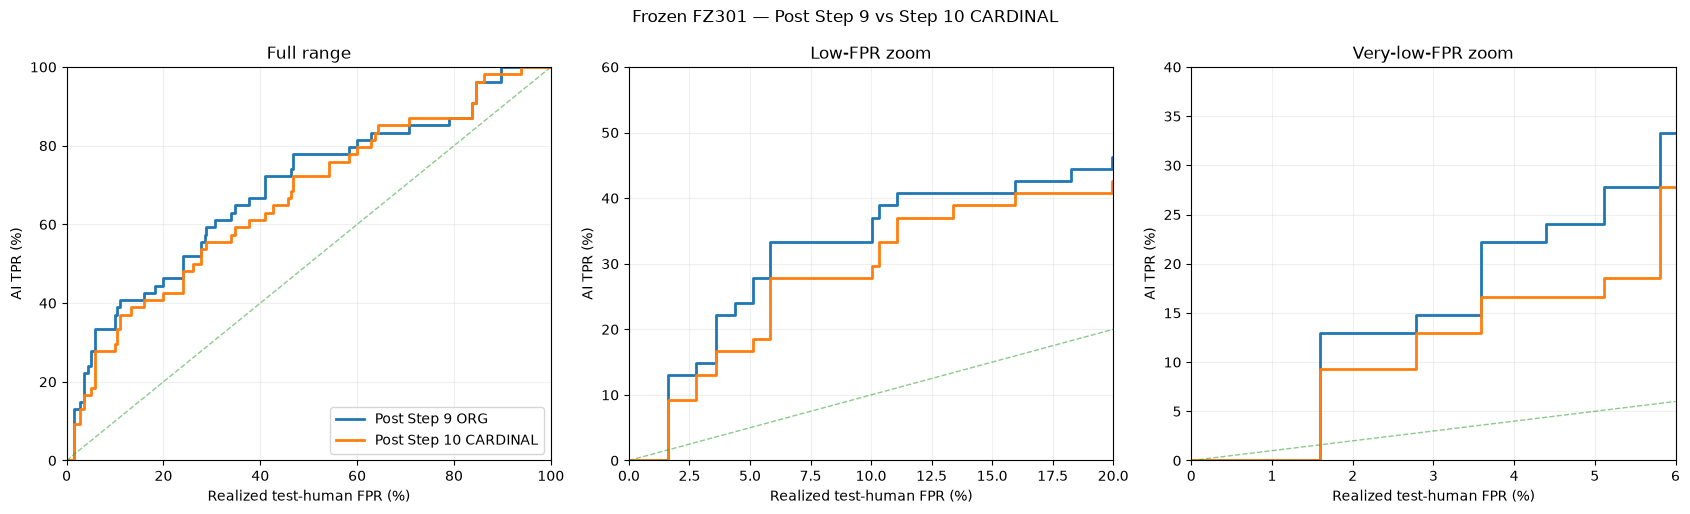

In [16]:
# C04c Step 10 — exact frozen-FZ301 evaluation + TPR staircase.
#
# Compares:
#   Post Step 9 ORG
#   Post Step 10 CARDINAL
#
# Uses the SAME frozen FZ301, same calibration humans,
# same test humans, same genre weights, and strict score > threshold.

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

from sklearn.metrics import roc_curve, auc

# C04c patch — dependency used by the imported FZ301 coreference block.

from collections import defaultdict

print("✓ defaultdict imported for frozen FZ301 extractor.")

# ============================================================
# Load the exact FZ301 extraction functions from C04b.
#
# C04c intentionally started as an audit notebook, so it did
# not duplicate the full 301-feature extractor.
# ============================================================

if "fz118_frame" not in globals() or "extension_vector" not in globals():

    c04b_notebooks = sorted(
        (ROOT / "experiments").glob(
            "C04b*ORG*explicitization*.ipynb"
        )
    )

    assert len(c04b_notebooks) == 1, (
        "Expected exactly one C04b ORG-explicitization notebook under "
        f"{ROOT / 'experiments'}, found:\n"
        + "\n".join(map(str, c04b_notebooks))
    )

    c04b_nb = json.loads(
        c04b_notebooks[0].read_text()
    )

    code_sources = [
        "".join(cell["source"])
        for cell in c04b_nb["cells"]
        if cell["cell_type"] == "code"
    ]

    fz118_src = next(
        s for s in code_sources
        if "Exact frozen project FZ118 extractor" in s
    )

    fz301_src = next(
        s for s in code_sources
        if "Freeze the project FZ301 v1 feature contract" in s
    )

    # Strip C04b's own sanity-run tail; we only need definitions here.
    marker = "# Sanity check directly against unchanged RAID rows."

    if marker in fz118_src:
        fz118_src = (
            fz118_src.split(marker)[0]
        )

    # Dependencies used by the exact extractor.
    import textstat
    import importlib.metadata as importlib_metadata
    from empath import Empath

    empath = Empath()

    exec(
        fz118_src,
        globals(),
    )

    exec(
        fz301_src,
        globals(),
    )


assert F301 == list(
    C04_MANIFEST[
        "feature_names"
    ]
)

assert len(F301) == 301


# ============================================================
# Exact feature extraction for Step 9 and Step 10.
# ============================================================

def extension_frame(
    texts,
    desc,
    batch_size=64,
):

    rows = []

    texts = list(
        map(
            str,
            texts,
        )
    )

    for i, doc in enumerate(
        nlp.pipe(
            texts,
            batch_size=batch_size,
        ),
        start=1,
    ):

        rows.append(
            extension_vector(
                doc
            )
        )

        if (
            i % 10 == 0
            or i == len(texts)
        ):
            print(
                f"{desc}: "
                f"{i}/{len(texts)}"
            )

    return pd.DataFrame(
        np.vstack(
            rows
        ),
        columns=EXT_NAMES,
    )


# Step 9.
X_step9 = pd.concat(
    [
        fz118_frame(
            step9.text.tolist()
        ),

        extension_frame(
            step9.text.tolist(),
            "Step 9",
        ),
    ],
    axis=1,
)[F301]


# Step 10.
X_step10 = pd.concat(
    [
        fz118_frame(
            step10_cases.text.tolist()
        ),

        extension_frame(
            step10_cases.text.tolist(),
            "Step 10",
        ),
    ],
    axis=1,
)[F301]


assert (
    X_step9.shape
    == (54, 301)
)

assert (
    X_step10.shape
    == (54, 301)
)


# Save exact transformed feature matrices.
X_step9_save = (
    X_step9.copy()
)

X_step9_save.insert(
    0,
    "case_id",
    step9.case_id,
)

X_step9_save.to_csv(
    STEP10_OUT
    / "post_step9_FZ301_features.csv",
    index=False,
)


X_step10_save = (
    X_step10.copy()
)

X_step10_save.insert(
    0,
    "case_id",
    step10_cases.case_id,
)

X_step10_save.to_csv(
    STEP10_OUT
    / "post_step10_FZ301_features.csv",
    index=False,
)


# ============================================================
# Reconstruct fixed RAID human calibration/test population.
# ============================================================

features_all = pd.read_parquet(
    BASE
    / "fz118_paired_features.parquet"
)

raid = (
    features_all.loc[
        features_all.dataset.eq(
            "raid"
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


raid_ext = (
    pd.read_parquet(
        CACHE
        / "raid_extensions.parquet"
    )
    .set_index(
        "source_id"
    )
    .loc[
        raid.source_id,
        EXT_NAMES,
    ]
    .reset_index(
        drop=True
    )
)


XR = pd.concat(
    [
        raid[
            FEATURE_NAMES
        ].reset_index(
            drop=True
        ),

        raid_ext,
    ],
    axis=1,
)[F301]


mix = (
    step10_cases.domain
    .value_counts(
        normalize=True
    )
)


def human_mask(
    split,
):

    return (
        raid.split.eq(
            split
        )
        & raid.label.eq(
            0
        )
        & raid.domain.isin(
            mix.index
        )
    ).to_numpy()


calmask = human_mask(
    "validation"
)

hmask = human_mask(
    "test"
)


def genre_weights(
    mask,
):

    g = raid.loc[
        mask,
        "domain",
    ]

    counts = (
        g.value_counts()
    )

    w = np.asarray(
        [
            mix[x]
            / counts[x]
            for x in g
        ],
        dtype=float,
    )

    assert np.isclose(
        w.sum(),
        1.0,
    )

    return w


wc = genre_weights(
    calmask
)

wh = genre_weights(
    hmask
)


cal_scores = (
    fz301.predict_proba(
        XR.loc[
            calmask,
            F301,
        ]
    )[:, 1]
)


human_scores = (
    fz301.predict_proba(
        XR.loc[
            hmask,
            F301,
        ]
    )[:, 1]
)


step9_scores = (
    fz301.predict_proba(
        X_step9
    )[:, 1]
)


step10_scores = (
    fz301.predict_proba(
        X_step10
    )[:, 1]
)


# ============================================================
# Sanity: Step 9 must reproduce accepted C04b result.
# ============================================================

np.testing.assert_allclose(
    step9_scores.mean(),
    0.4983782026,
    atol=5e-6,
    rtol=0,
)


def weighted_auc(
    ai_scores,
):

    fpr, tpr, _ = roc_curve(
        np.r_[
            np.zeros(
                len(
                    human_scores
                )
            ),
            np.ones(
                len(
                    ai_scores
                )
            ),
        ],

        np.r_[
            human_scores,
            ai_scores,
        ],

        sample_weight=np.r_[
            wh,
            np.ones(
                len(
                    ai_scores
                )
            )
            / len(
                ai_scores
            ),
        ],

        drop_intermediate=False,
    )

    return auc(
        fpr,
        tpr,
    )


stage_summary = pd.DataFrame([
    {
        "stage":
            "Post Step 9 ORG",

        "AUROC":
            weighted_auc(
                step9_scores
            ),

        "mean_AI_score":
            step9_scores.mean(),

        "median_AI_score":
            np.median(
                step9_scores
            ),
    },

    {
        "stage":
            "Post Step 10 CARDINAL",

        "AUROC":
            weighted_auc(
                step10_scores
            ),

        "mean_AI_score":
            step10_scores.mean(),

        "median_AI_score":
            np.median(
                step10_scores
            ),
    },
])


stage_summary[
    "AUROC_change_vs_step9"
] = (
    stage_summary.AUROC
    - stage_summary.iloc[
        0
    ].AUROC
)


stage_summary[
    "mean_score_change_vs_step9"
] = (
    stage_summary.mean_AI_score
    - stage_summary.iloc[
        0
    ].mean_AI_score
)


display(
    stage_summary
)


stage_summary.to_csv(
    STEP10_OUT
    / "stage_summary.csv",
    index=False,
)


# ============================================================
# Exact calibration-threshold staircase.
#
# Thresholds are defined ONLY from fixed calibration humans.
# Strict score > threshold.
# ============================================================

cuts = np.r_[
    np.inf,
    np.unique(
        cal_scores
    )[::-1],
    -np.inf,
]


stair = pd.DataFrame({
    "threshold":
        cuts,

    "calibration_FPR":
        [
            wc[
                cal_scores
                > c
            ].sum()
            for c
            in cuts
        ],

    "test_FPR":
        [
            wh[
                human_scores
                > c
            ].sum()
            for c
            in cuts
        ],

    "Post Step 9 ORG":
        [
            (
                step9_scores
                > c
            ).mean()
            for c
            in cuts
        ],

    "Post Step 10 CARDINAL":
        [
            (
                step10_scores
                > c
            ).mean()
            for c
            in cuts
        ],
})


stair.to_csv(
    STEP10_OUT
    / "detailed_TPR_staircase.csv",
    index=False,
)


# ============================================================
# Plot — same three-panel style as C03/C04.
# ============================================================

fig, axs = plt.subplots(
    1,
    3,
    figsize=(
        17,
        5.2,
    ),
)


panels = [
    (
        (0, 100),
        (0, 100),
        "Full range",
    ),

    (
        (0, 20),
        (0, 60),
        "Low-FPR zoom",
    ),

    (
        (0, 6),
        (0, 40),
        "Very-low-FPR zoom",
    ),
]


for (
    ax,
    (
        xlim,
        ylim,
        title,
    ),
) in zip(
    axs,
    panels,
):

    for label in [
        "Post Step 9 ORG",
        "Post Step 10 CARDINAL",
    ]:

        ax.step(
            stair[
                "test_FPR"
            ]
            * 100,

            stair[
                label
            ]
            * 100,

            where="post",
            linewidth=2,
            label=label,
        )


    hi = min(
        xlim[1],
        ylim[1],
    )


    ax.plot(
        [
            0,
            hi,
        ],
        [
            0,
            hi,
        ],
        "--",
        linewidth=1,
        alpha=0.55,
    )


    ax.set_xlim(
        *xlim
    )

    ax.set_ylim(
        *ylim
    )

    ax.set_xlabel(
        "Realized test-human FPR (%)"
    )

    ax.set_ylabel(
        "AI TPR (%)"
    )

    ax.set_title(
        title
    )

    ax.grid(
        alpha=0.2
    )


axs[0].legend(
    loc="lower right"
)


fig.suptitle(
    "Frozen FZ301 — Post Step 9 vs Step 10 CARDINAL"
)


fig.tight_layout()


for folder in [
    STEP10_OUT,
    ROOT / "figures",
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

    fig.savefig(
        folder
        / "C04c_FZ301_step9_vs_step10_CARDINAL_TPR_staircase.pdf",
        bbox_inches="tight",
    )

    fig.savefig(
        folder
        / "C04c_FZ301_step9_vs_step10_CARDINAL_TPR_staircase.png",
        dpi=300,
        bbox_inches="tight",
    )


plt.show()

CARDINAL contribution movement:


,feature,Step9_gap,Step10_gap,Step10_minus_Step9,Step10_ci_low,Step10_ci_high
0,ner_CARDINAL_sentence_max,0.002319,-0.000757,-0.003077,-0.001477,-0.000128
1,ner_CARDINAL_sentence_std,0.001764,-0.001879,-0.003642,-0.002574,-0.001217
2,ner_CARDINAL_entity_share,0.001609,-0.002193,-0.003803,-0.003390,-0.001148
3,ner_CARDINAL_sentence_mean,0.001610,-0.002247,-0.003857,-0.002923,-0.001623



Largest contribution changes:


,feature,Step9_gap,Step10_gap,Step10_minus_Step9
0,ner_CARDINAL_sentence_mean,0.001610,-0.002247,-0.003857
1,ner_CARDINAL_entity_share,0.001609,-0.002193,-0.003803
2,ner_CARDINAL_sentence_std,0.001764,-0.001879,-0.003642
3,ner_CARDINAL_sentence_max,0.002319,-0.000757,-0.003077
4,pos_NUM_sentence_mean,0.000820,-0.001847,-0.002666
5,pos_NUM_token_share,0.000269,-0.001662,-0.001931
6,pos_NUM_sentence_std,0.000388,-0.000918,-0.001306
7,punct_relative_colon,-0.001432,-0.000849,0.000582
8,pos_X_token_share,0.001234,0.000771,-0.000463
9,pos_NUM_sentence_max,-0.000410,-0.000862,-0.000452


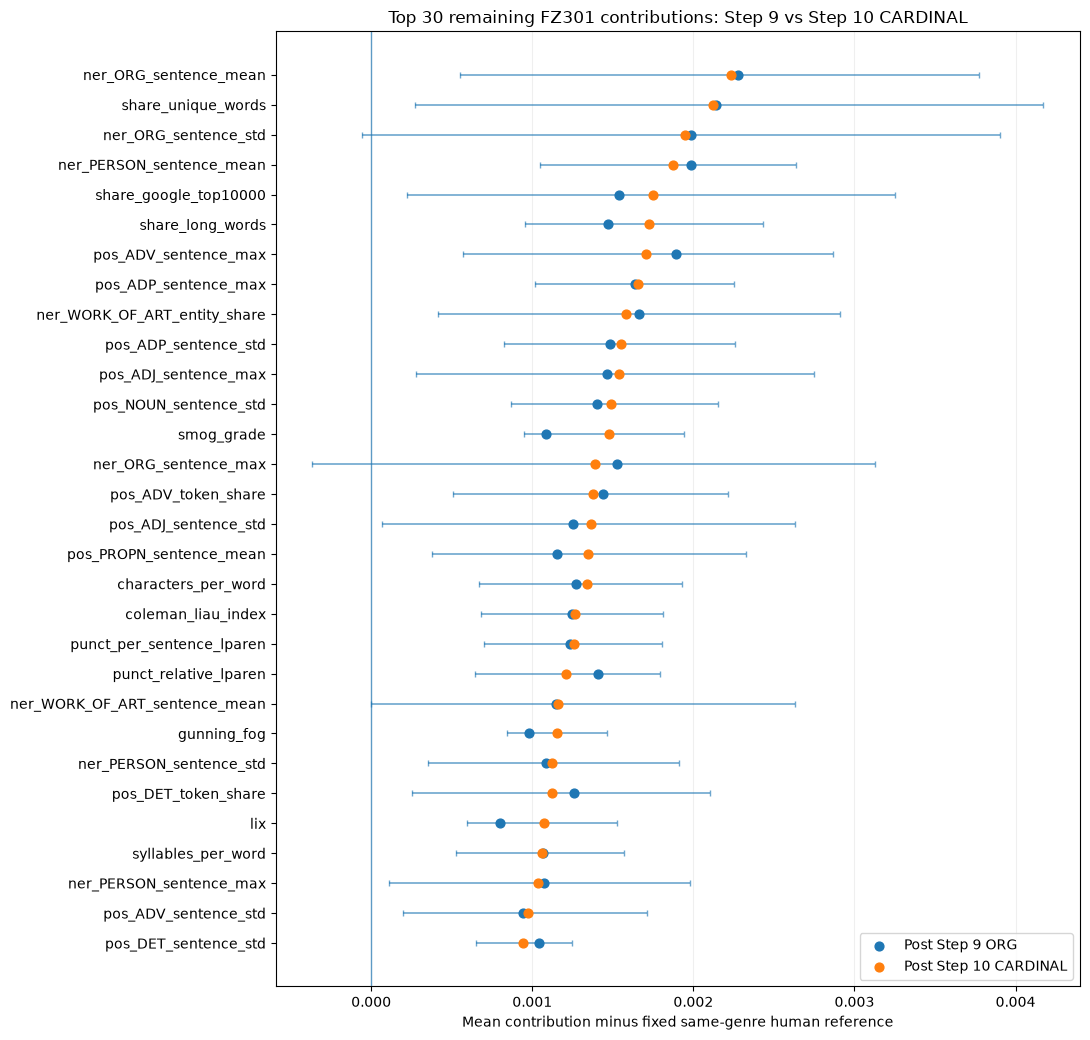

In [17]:
# Step 10 contribution graph — frozen FZ301, Step 9 vs Step 10.

def forest_contributions(model, frame):
    X = np.asarray(frame, dtype=np.float32)
    out = np.zeros_like(X, dtype=float)
    bias = 0.0
    for est in model.estimators_:
        tree = est.tree_
        value = tree.value[:, 0, :].astype(float)
        prob = value[:, 1] / value.sum(axis=1)
        bias += prob[0] / len(model.estimators_)
        for i, row in enumerate(X):
            node = 0
            while tree.children_left[node] != tree.children_right[node]:
                f = tree.feature[node]
                child = tree.children_left[node] if row[f] <= tree.threshold[node] else tree.children_right[node]
                out[i, f] += (prob[child] - prob[node]) / len(model.estimators_)
                node = child
    np.testing.assert_allclose(
        bias + out.sum(axis=1),
        model.predict_proba(frame)[:, 1],
        atol=1e-8, rtol=0,
    )
    return out

step9_contrib = forest_contributions(fz301, X_step9)
step10_contrib = forest_contributions(fz301, X_step10)
human_contrib = forest_contributions(fz301, XR.loc[hmask, F301])

# Fixed same-genre human contribution reference.
human_ref = (
    pd.DataFrame(human_contrib, columns=F301)
    .assign(domain=raid.loc[hmask, "domain"].to_numpy())
    .groupby("domain")[F301]
    .mean()
)
ref = human_ref.loc[step10_cases.domain].to_numpy()

step9_gap = step9_contrib - ref
step10_gap = step10_contrib - ref

# Genre-stratified bootstrap CI for current Step 10.
rng = np.random.default_rng(20260912)
B = 2000
boot = np.zeros((B, len(F301)), dtype=float)
domains = step10_cases.domain.to_numpy()

for domain in sorted(step10_cases.domain.unique()):
    ix = np.flatnonzero(domains == domain)
    draw = rng.choice(ix, size=(B, len(ix)), replace=True)
    boot += (len(ix) / len(step10_cases)) * step10_gap[draw].mean(axis=1)

ci_low, ci_high = np.quantile(boot, [0.025, 0.975], axis=0)

contribution_compare = pd.DataFrame({
    "feature": F301,
    "Step9_gap": step9_gap.mean(axis=0),
    "Step10_gap": step10_gap.mean(axis=0),
    "Step10_ci_low": ci_low,
    "Step10_ci_high": ci_high,
})
contribution_compare["Step10_minus_Step9"] = contribution_compare.Step10_gap - contribution_compare.Step9_gap
contribution_compare["abs_change"] = contribution_compare.Step10_minus_Step9.abs()

contribution_compare.to_csv(
    STEP10_OUT / "step9_vs_step10_contributions.csv",
    index=False,
)

print("CARDINAL contribution movement:")
display(
    contribution_compare.loc[
        contribution_compare.feature.isin(CARDINAL_FEATURES),
        ["feature", "Step9_gap", "Step10_gap", "Step10_minus_Step9",
         "Step10_ci_low", "Step10_ci_high"]
    ].sort_values("Step10_gap", ascending=False).reset_index(drop=True)
)

print("\nLargest contribution changes:")
display(
    contribution_compare.sort_values("abs_change", ascending=False)
    .head(20)[["feature", "Step9_gap", "Step10_gap", "Step10_minus_Step9"]]
    .reset_index(drop=True)
)

# Top 30 current residuals.
top = (
    contribution_compare.sort_values("Step10_gap", ascending=False)
    .head(30).iloc[::-1].reset_index(drop=True)
)

y = np.arange(len(top))
cur = top.Step10_gap.to_numpy(float)
xerr = np.vstack([
    cur - top.Step10_ci_low.to_numpy(float),
    top.Step10_ci_high.to_numpy(float) - cur,
])

fig, ax = plt.subplots(figsize=(11, 10.5))
ax.errorbar(cur, y, xerr=xerr, fmt="none", capsize=2, linewidth=1.2, alpha=0.65)
ax.scatter(top.Step9_gap, y, label="Post Step 9 ORG", s=40, zorder=3)
ax.scatter(top.Step10_gap, y, label="Post Step 10 CARDINAL", s=40, zorder=4)
ax.axvline(0, linewidth=1, alpha=0.7)
ax.set_yticks(y)
ax.set_yticklabels(top.feature)
ax.set_xlabel("Mean contribution minus fixed same-genre human reference")
ax.set_title("Top 30 remaining FZ301 contributions: Step 9 vs Step 10 CARDINAL")
ax.legend()
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()

for folder in [STEP10_OUT, ROOT / "figures"]:
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / "C04c_FZ301_step9_vs_step10_CARDINAL_contributions.pdf", bbox_inches="tight")
    fig.savefig(folder / "C04c_FZ301_step9_vs_step10_CARDINAL_contributions.png", dpi=300, bbox_inches="tight")

plt.show()